# PD04 · Limpieza e integración territorial

Continuación de PD01–PD03 basada en las clases del 9 y 10 de octubre de 2026. Tiempo orientativo: 270 minutos, con el entorno y los datos preparados.

Copia esta plantilla a `soluciones/` conservando su nombre. Escribe allí el código y las interpretaciones. Las celdas iniciales muestran las lecturas; las actividades quedan a tu cargo. Antes de entregar, reinicia el kernel y ejecuta todas las celdas en orden.

Utiliza directamente las API de pandas, GeoPandas y, en PD05, Polars. Mantén visibles las conversiones, máscaras, agrupaciones, uniones y exportaciones. No uses `talleres.py`, `pqrs_talleres.py`, comandos de shell ni funciones que resuelvan varias etapas sin mostrar su implementación. Un bucle de medición es válido si su cuerpo contiene las operaciones que estás midiendo. No instales paquetes desde el notebook.

[Índice](../ejercicios/README.md) · [Pandas](../docs/manual-pandas.md) · [Polars](../docs/manual-polars.md) · [GeoPandas](../docs/manual-geopandas.md)

## Ubicación de trabajo

Abre Jupyter desde la raíz del repositorio con el entorno del curso activo. Cambia `REPO` por la ruta real de tu copia. Las rutas son explícitas y funcionan tanto desde `ejercicios/` como desde `soluciones/`. Si falta un archivo, revisa su ubicación; no sustituyas silenciosamente la entrada por otro dataset.

## Pregunta y entradas

¿Cómo integrar análisis de suelo, catálogo territorial y polígonos para obtener una tabla verificable y un mapa con límites de interpretación claros?

| Fuente | Lectura directa | Uso |
|---|---|---|
| `agrosavia.csv` | `pd.read_csv` | Análisis, fechas y medidas con tipos y marcadores variados. |
| `divipola.csv` | `pd.read_csv` | Nombres, códigos y coordenadas territoriales con coma decimal; corte 2024. |
| `dane_municipios.zip` | `gpd.read_file` | Polígonos municipales MGN 2025 y código `mpio_cdpmp`. |
| `igac_capacidad.json` | `gpd.read_file` | Muestra GeoJSON de cinco polígonos de capacidad de uso. |

Primero integra las dos tablas con pandas. Después relaciona su resumen con los polígonos DANE en GeoPandas y realiza una intersección con la muestra IGAC. Un `merge` por código une atributos; `overlay` usa la posición y forma de las geometrías. Explica esa diferencia en tus resultados.

Las coordenadas de DIVIPOLA no son ubicaciones de muestras de suelo. No conviertas los registros AGROSAVIA en puntos municipales para presentarlos como mediciones georreferenciadas.

Prepara el ZIP siguiendo la [descarga manual DANE](../docs/entorno.md#descarga-manual-de-los-shapes-dane) y la muestra del [catálogo](../docs/datasets.md). Conserva juntos los componentes del Shapefile dentro del ZIP. Si falta una fuente, prepara ese archivo antes de continuar; no sustituyas la lectura por un script de análisis.

`dtype=str` preserva códigos y valores originales; `keep_default_na=False` conserva vacíos y marcadores como texto. Revisa las opciones de cada lectura.

In [1]:
import os
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

REPO = "/mnt/c/Users/TUPTC/bigdata/big-data-postgraduate"
RAW = REPO + "/kit/data/raw"
OUT = REPO + "/kit/salidas/soluciones/PD04"
os.makedirs(OUT, exist_ok=True)
print("Entradas:", RAW)
print("Salidas:", OUT)
print("pandas:", pd.__version__, "GeoPandas:", gpd.__version__)

Entradas: /mnt/c/Users/TUPTC/bigdata/big-data-postgraduate/kit/data/raw
Salidas: /mnt/c/Users/TUPTC/bigdata/big-data-postgraduate/kit/salidas/soluciones/PD04
pandas: 2.2.3 GeoPandas: 1.2.0


In [2]:
suelo = pd.read_csv(
    RAW + "/agrosavia.csv",
    sep=",",
    encoding="utf-8-sig",
    dtype=str,
    keep_default_na=False
)
display(suelo.head())
print(suelo.shape)

,Secuencial,Fecha de Análisis,Departamento,Municipio,Cultivo,Estado,Tiempo de establecimiento,Topografia,Drenaje,Riego,...,Conductividad electrica,Hierro disponible olsen,Cobre disponible,Manganeso disponible Olsen,Zinc disponible Olsen,Boro disponible,Hierro disponible doble acido,Cobre disponible doble acido,Manganeso disponible doble acido,Zinc disponible doble acido
0,1,7/01/2014,NARIÑO,SAN ANDRÉS DE TUMACO,No Indica,No indica,No indica,No indica,No indica,No indica,...,0.133,66.39,1.700,1.700,1.5,0.187,ND,ND,ND,ND
1,2,21/08/2014,HUILA,SANTA MARÍA,Granadilla,Establecido,De 1 a 5 años,Pendiente,Buen drenaje,No Tiene,...,2.749,250.9,3.7,29.4,28.70,2.084,ND,ND,ND,ND
2,3,22/08/2014,ANTIOQUIA,LIBORINA,Café,Por establecer,No indica,Pendiente,Mal drenaje,No Tiene,...,0.328,390,11.10,8.299,5,0.085,ND,ND,ND,ND
3,4,22/08/2014,ANTIOQUIA,LIBORINA,Maracuyá,Por establecer,No indica,Ondulado,Mal drenaje,No Tiene,...,0.171,200,4.2,4.699,1,0.229,ND,ND,ND,ND
4,5,22/08/2014,ANTIOQUIA,LIBORINA,Café,Por establecer,No indica,Ondulado,Mal drenaje,No Tiene,...,0.323,117.9,3.8,4.600,0.700,0.139,ND,ND,ND,ND


(92738, 32)


In [3]:
territorio = pd.read_csv(
    RAW + "/divipola.csv",
    sep=",",
    encoding="utf-8-sig",
    dtype=str,
    keep_default_na=False
)
display(territorio.head())
print(territorio.shape)

,Código Departamento,Nombre Departamento,Código Municipio,Nombre Municipio,Tipo: Municipio / Isla / Área no municipalizada,longitud,Latitud
0,05,ANTIOQUIA,05001,MEDELLÍN,Municipio,"-75,581775","6,246631"
1,05,ANTIOQUIA,05002,ABEJORRAL,Municipio,"-75,428739","5,789315"
2,05,ANTIOQUIA,05004,ABRIAQUÍ,Municipio,"-76,064304","6,632282"
3,05,ANTIOQUIA,05021,ALEJANDRÍA,Municipio,"-75,141346","6,376061"
4,05,ANTIOQUIA,05030,AMAGÁ,Municipio,"-75,702188","6,038708"


(1122, 7)


## 1. Diagnóstico y contrato · 20 minutos

Muestra dimensiones, columnas y tipos de ambas tablas. Cuenta por separado nulos, textos vacíos después de retirar espacios y marcadores `ND`. Examina fecha, pH, nombres territoriales y coordenadas.

Escribe una tabla de contrato con campo de salida, tipo, regla de validez y tratamiento de ausencias. Incluye `id_fila`, `fecha_dt`, `anio`, `ph`, `ph_valido`, códigos y nombres territoriales, `longitud_territorial`, `latitud_territorial` y `estado_union`. Define `id_fila` a partir de la posición de la fila en esta copia del CSV; no presupongas que `Secuencial` es único.

**Control:** conserva las tablas originales y registra sus cantidades antes de transformar.

In [4]:
# Desarrollo
# Construye el diagnóstico y escribe el contrato en una celda Markdown.
suelo.info()
print(suelo.shape)
display(suelo.dtypes)
print(suelo.columns.tolist())
print("suelo frente a territorio:", suelo.columns.equals(territorio.columns))
print("-------------------------")
territorio.info()
print(territorio.shape)



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 92738 entries, 0 to 92737
Data columns (total 32 columns):
 #   Column                              Non-Null Count  Dtype 
---  ------                              --------------  ----- 
 0   Secuencial                          92738 non-null  object
 1   Fecha de Análisis                   92738 non-null  object
 2   Departamento                        92738 non-null  object
 3   Municipio                           92738 non-null  object
 4   Cultivo                             92738 non-null  object
 5   Estado                              92738 non-null  object
 6   Tiempo de establecimiento           92738 non-null  object
 7   Topografia                          92738 non-null  object
 8   Drenaje                             92738 non-null  object
 9   Riego                               92738 non-null  object
 10  Fertilizantes aplicados             92738 non-null  object
 11  pH agua:suelo                       92738 non-null  ob

Secuencial                            object
Fecha de Análisis                     object
Departamento                          object
Municipio                             object
Cultivo                               object
Estado                                object
Tiempo de establecimiento             object
Topografia                            object
Drenaje                               object
Riego                                 object
Fertilizantes aplicados               object
pH agua:suelo                         object
Materia organica                      object
Fósforo Bray II                       object
Azufre Fosfato monocalcico            object
Acidez Intercambiable                 object
Aluminio intercambiable               object
Calcio intercambiable                 object
Magnesio intercambiable               object
Potasio intercambiable                object
Sodio intercambiable                  object
capacidad de intercambio cationico    object
Conductivi

['Secuencial', 'Fecha de Análisis', 'Departamento', 'Municipio', 'Cultivo', 'Estado', 'Tiempo de establecimiento', 'Topografia', 'Drenaje', 'Riego', 'Fertilizantes aplicados', 'pH agua:suelo', 'Materia organica', 'Fósforo Bray II', 'Azufre Fosfato monocalcico', 'Acidez Intercambiable', 'Aluminio intercambiable', 'Calcio intercambiable', 'Magnesio intercambiable', 'Potasio intercambiable', 'Sodio intercambiable', 'capacidad de intercambio cationico', 'Conductividad electrica', 'Hierro disponible olsen', 'Cobre disponible', 'Manganeso disponible Olsen', 'Zinc disponible Olsen', 'Boro disponible', 'Hierro disponible doble acido', 'Cobre disponible doble acido', 'Manganeso disponible doble acido', 'Zinc disponible doble \xa0acido']
suelo frente a territorio: False
-------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1122 entries, 0 to 1121
Data columns (total 7 columns):
 #   Column                                           Non-Null Count  Dtype 
---  ------         

In [5]:
campos_suelo = [
    "Fecha de Análisis",
    "pH agua:suelo",
    "Departamento",
    "Municipio"
]

campos_territorio = [
    "Código Departamento",
    "Código Municipio",
    "Nombre Departamento",
    "Nombre Municipio",
    "longitud",
    "Latitud"
]

def perfil_ausencias(df, campos):
    perfil = pd.DataFrame(index=campos)
    perfil["nulos"] = df[campos].isna().sum()

    for campo in campos:
        valores = df[campo].astype("string").str.strip()
        perfil.loc[campo, "vacios"] = (
            valores.eq("").fillna(False).sum()
        )
        perfil.loc[campo, "ND"] = (
            valores.str.upper().eq("ND").fillna(False).sum()
        )

    return perfil.astype("int64")

print("Ausencias en suelo")
display(perfil_ausencias(suelo, campos_suelo))

print("Ausencias en territorio")
display(perfil_ausencias(territorio, campos_territorio))



Ausencias en suelo


,nulos,vacios,ND
Fecha de Análisis,0,0,0
pH agua:suelo,0,0,0
Departamento,0,0,0
Municipio,0,2,0


Ausencias en territorio


,nulos,vacios,ND
Código Departamento,0,0,0
Código Municipio,0,0,0
Nombre Departamento,0,0,0
Nombre Municipio,0,0,0
longitud,0,0,0
Latitud,0,0,0


In [6]:
import pandas as pd

# Copias de trabajo
suelo_trabajo = suelo[campos_suelo].copy()
territorio_trabajo = territorio[campos_territorio].copy()

# Identificador de fila del registro de suelo
suelo_trabajo.insert(0, "id_fila", range(len(suelo_trabajo)))

# Fecha y año
suelo_trabajo["fecha_dt"] = pd.to_datetime(
    suelo_trabajo["Fecha de Análisis"].astype("string").str.strip(),
    format="%d/%m/%Y",
    errors="coerce"
)
suelo_trabajo["anio"] = suelo_trabajo["fecha_dt"].dt.year.astype("Int64")

# pH
ph_texto = suelo_trabajo["pH agua:suelo"].astype("string").str.strip()
ph_ausente = (
    ph_texto.isna()
    | ph_texto.eq("")
    | ph_texto.str.upper().eq("ND")
)

suelo_trabajo["ph"] = pd.to_numeric(
    ph_texto.mask(ph_ausente),
    errors="coerce"
)
suelo_trabajo["ph_valido"] = (
    suelo_trabajo["ph"].between(0, 14).fillna(False)
)

# Normalizar nombres para poder compararlos
def normalizar_nombre(serie):
    return (
        serie.astype("string")
        .str.strip()
        .str.upper()
        .str.normalize("NFKD")
        .str.replace(r"[\u0300-\u036f]", "", regex=True)
        .str.replace(r"\s+", " ", regex=True)
    )

suelo_trabajo["_depto"] = normalizar_nombre(suelo_trabajo["Departamento"])
suelo_trabajo["_municipio"] = normalizar_nombre(suelo_trabajo["Municipio"])

territorio_trabajo["_depto"] = normalizar_nombre(
    territorio_trabajo["Nombre Departamento"]
)
territorio_trabajo["_municipio"] = normalizar_nombre(
    territorio_trabajo["Nombre Municipio"]
)

# Limpiar y convertir coordenadas
for original, salida in [
    ("longitud", "longitud_territorial"),
    ("Latitud", "latitud_territorial")
]:
    texto = territorio_trabajo[original].astype("string").str.strip()
    ausente = texto.isna() | texto.eq("") | texto.str.upper().eq("ND")

    territorio_trabajo[salida] = pd.to_numeric(
        texto.mask(ausente).str.replace(",", ".", regex=False),
        errors="coerce"
    )

# Evitar multiplicar filas si hay territorios duplicados
claves = ["_depto", "_municipio"]
territorio_claves = territorio_trabajo.dropna(subset=claves)

duplicados = territorio_claves.duplicated(claves, keep=False)
if duplicados.any():
    raise ValueError(
        "Hay nombres de departamento y municipio duplicados en territorio. "
        "Debes revisar esos registros antes de unir."
    )

# Unir por departamento y municipio
tabla_final = suelo_trabajo.merge(
    territorio_trabajo[
        claves + [
            "Código Departamento",
            "Código Municipio",
            "longitud_territorial",
            "latitud_territorial"
        ]
    ],
    on=claves,
    how="left",
    validate="many_to_one",
    indicator=True
)

# Estado de la unión
tabla_final["estado_union"] = tabla_final["_merge"].map({
    "both": "encontrado",
    "left_only": "sin_correspondencia"
})

# Una sola columna de departamento y municipio en el resultado
tabla_final = tabla_final.drop(
    columns=[
        "_depto", "_municipio", "_merge",
        "Fecha de Análisis", "pH agua:suelo"
    ]
)
assert tabla_final.shape == (92738, 12)
display(tabla_final)
print("-------------------")
tabla_final.info()
print("-------------------")
display("Nulos:", tabla_final.isna().sum())
display("Textos vacíos:", tabla_final.eq("").sum())
display("Marcadores ND:", tabla_final.apply(lambda col: col.astype(str).str.upper().eq("ND").sum()))
print("-----------------------")
print(tabla_final["estado_union"].value_counts())
   

,id_fila,Departamento,Municipio,fecha_dt,anio,ph,ph_valido,Código Departamento,Código Municipio,longitud_territorial,latitud_territorial,estado_union
0,0,NARIÑO,SAN ANDRÉS DE TUMACO,2014-01-07,2014,5.64,True,52,52835,-78.764073,1.807399,encontrado
1,1,HUILA,SANTA MARÍA,2014-08-21,2014,4.24,True,41,41676,-75.586223,2.939603,encontrado
2,2,ANTIOQUIA,LIBORINA,2014-08-22,2014,5.22,True,05,05411,-75.812838,6.677316,encontrado
3,3,ANTIOQUIA,LIBORINA,2014-08-22,2014,5.45,True,05,05411,-75.812838,6.677316,encontrado
4,4,ANTIOQUIA,LIBORINA,2014-08-22,2014,5.43,True,05,05411,-75.812838,6.677316,encontrado
...,...,...,...,...,...,...,...,...,...,...,...,...
92733,92733,SANTANDER,SOCORRO,2025-04-07,2025,4.92,True,68,68755,-73.261198,6.46387,encontrado
92734,92734,SANTANDER,PALMAS DEL SOCORRO,2025-04-04,2025,4.96,True,68,68524,-73.287764,6.406139,encontrado
92735,92735,SANTANDER,PALMAS DEL SOCORRO,2025-04-03,2025,4.7,True,68,68524,-73.287764,6.406139,encontrado
92736,92736,SANTANDER,PALMAS DEL SOCORRO,2025-04-04,2025,4.8,True,68,68524,-73.287764,6.406139,encontrado


-------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 92738 entries, 0 to 92737
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   id_fila               92738 non-null  int64         
 1   Departamento          92738 non-null  object        
 2   Municipio             92738 non-null  object        
 3   fecha_dt              92738 non-null  datetime64[ns]
 4   anio                  92738 non-null  Int64         
 5   ph                    92727 non-null  Float64       
 6   ph_valido             92738 non-null  boolean       
 7   Código Departamento   90600 non-null  object        
 8   Código Municipio      90600 non-null  object        
 9   longitud_territorial  90600 non-null  Float64       
 10  latitud_territorial   90600 non-null  Float64       
 11  estado_union          92738 non-null  object        
dtypes: Float64(3), Int64(1), boolean(1), datetime64[ns](1)

'Nulos:'

id_fila                    0
Departamento               0
Municipio                  0
fecha_dt                   0
anio                       0
ph                        11
ph_valido                  0
Código Departamento     2138
Código Municipio        2138
longitud_territorial    2138
latitud_territorial     2138
estado_union               0
dtype: int64

'Textos vacíos:'

id_fila                 0
Departamento            0
Municipio               2
fecha_dt                0
anio                    0
ph                      0
ph_valido               0
Código Departamento     0
Código Municipio        0
longitud_territorial    0
latitud_territorial     0
estado_union            0
dtype: Int64

'Marcadores ND:'

id_fila                 0
Departamento            0
Municipio               0
fecha_dt                0
anio                    0
ph                      0
ph_valido               0
Código Departamento     0
Código Municipio        0
longitud_territorial    0
latitud_territorial     0
estado_union            0
dtype: int64

-----------------------
estado_union
encontrado             90600
sin_correspondencia     2138
Name: count, dtype: int64


**Interpretación:**

_Se conservaron las tablas originales de agrosavia y divipola. Ademas, se reviso que la tabla de agrosavia tiene 92738 filas y 32 columnas(cada una nombrada como se puede ver en la primera tabla), mientras que la tabla de divipola tiene 1122 filas y 7 columnas._

_El tipo de los elementos de las dos tablas originales es "object".Tambien examino  fecha, pH, nombres territoriales y coordenadas en la tabla que correspondiera. Y se encontro que solo en la columna denominada "Municipio"  de la tabla "divipola" hay dos errores de texto vacio. Posteriormente, se creo una tabla contrato haciendo un merge entre divipola y agrosavia. La tabla incluia las siguientes: id_fila, fecha_dt, anio, ph, ph_valido, códigos y nombres territoriales, longitud_territorial, latitud_territorial y estado_union._

_Con la tabla obtenida se puede ver que el número de filas de la misma, es igual al número de filas de la tabla de agrosavia. Pero tambien aparecieron los dos errores de texto vacio, pero ademas con la union o uso del merge que se hizo tambien aparecieron valores nulos que en las tablas originales no existian y esto se puede deber a que estan escrito con un caracteristica que pandas no reconocio._

## 2. Conversión de medidas, fechas y coordenadas · 30 minutos

Crea columnas nuevas. Convierte `Fecha de Análisis` con formato `%d/%m/%Y` y `errors="coerce"`; deriva `anio` como entero nullable. Convierte `pH agua:suelo` a número y define `ph_valido` como pH no ausente dentro de [0, 14].

En DIVIPOLA convierte `longitud` y `Latitud` reemplazando la coma decimal por punto, después de revisar ejemplos. No apliques esa regla a todos los campos. Usa `pd.to_numeric(..., errors="coerce")`. Conserva valores originales y distingue ausencias de textos no vacíos que fallaron al convertir.

**Control:** muestra conteos y hasta cinco ejemplos por fallo. Revisa longitud en [−180, 180] y latitud en [−90, 90]. Un rango válido no demuestra que la ubicación sea correcta. No sustituyas ausencias por cero.

In [7]:
# Desarrollo
# Crea columnas tipadas y controles de conversión sin eliminar registros.
import pandas as pd

suelo_trabajo["fecha_dt"] = pd.to_datetime(
    suelo_trabajo["Fecha de Análisis"],
    errors="coerce",
    dayfirst=True
)

suelo_trabajo["anio"] = (
    suelo_trabajo["fecha_dt"]
    .dt.year
    .astype("Int64")
)

# Conservar el dato original
ph_original = suelo_trabajo["pH agua:suelo"]
ph_texto = ph_original.astype("string").str.strip()

# Identificar ausencias originales
ph_ausente = (
    ph_original.isna()
    | ph_texto.eq("").fillna(False)
    | ph_texto.str.upper().eq("ND").fillna(False)
)

# Convertir a número sin modificar el original
suelo_trabajo["ph"] = pd.to_numeric(
    ph_texto.mask(ph_ausente),
    errors="coerce"
)

# Identificar textos no vacíos que no pudieron convertirse
suelo_trabajo["ph_error_conversion"] = (
    ~ph_ausente
    & suelo_trabajo["ph"].isna()
)

# Validar el rango de pH entre 0 y 14, inclusive
suelo_trabajo["ph_valido"] = (
    suelo_trabajo["ph"].notna()
    & suelo_trabajo["ph"].between(0, 14)
)


for columna in ["longitud", "Latitud"]:

    original = territorio_trabajo[columna]
    texto = original.astype("string").str.strip()

    # Identificar ausencias originales
    ausente = (
        original.isna()
        | texto.eq("").fillna(False)
        | texto.str.upper().eq("ND").fillna(False)
    )

    # Reemplazar coma decimal únicamente en coordenadas
    texto_normalizado = texto.str.replace(
        ",", ".", regex=False
    )

    # Convertir a número
    territorio_trabajo[f"{columna}_num"] = pd.to_numeric(
        texto_normalizado.mask(ausente),
        errors="coerce"
    )

    # Distinguir errores de conversión de ausencias
    territorio_trabajo[f"{columna}_error_conversion"] = (
        ~ausente
        & territorio_trabajo[f"{columna}_num"].isna()
    )



errores_ph = suelo_trabajo.loc[
    suelo_trabajo["ph_error_conversion"],
    ["ph"]
]

errores_longitud = territorio_trabajo.loc[
    territorio_trabajo["longitud_error_conversion"],
    ["longitud", "longitud_num"]
]

errores_latitud = territorio_trabajo.loc[
    territorio_trabajo["Latitud_error_conversion"],
    ["Latitud", "Latitud_num"]
]

print("Errores de conversión del pH:", len(errores_ph))
display(errores_ph)

print("Errores de conversión de longitud:", len(errores_longitud))
display(errores_longitud)

print("Errores de conversión de latitud:", len(errores_latitud))
display(errores_latitud)




print("Datos de suelo:")
display(
    suelo_trabajo[
        [
            "id_fila",
            "Fecha de Análisis",
            "fecha_dt",
            "anio",
            "ph",
            "ph_valido",
            "ph_error_conversion"
        ]
    ].head(10)
)
print(suelo_trabajo.shape)
print("Datos territoriales:")
display(
    territorio_trabajo[
        [
            "longitud",
            "longitud_num",
            "longitud_error_conversion",
            "Latitud",
            "Latitud_num",
            "Latitud_error_conversion"
        ]
    ].head(10)
)
print( territorio_trabajo.shape)

Errores de conversión del pH: 11


,ph
7282,<NA>
46528,<NA>
46530,<NA>
52903,<NA>
56330,<NA>
57555,<NA>
61554,<NA>
61556,<NA>
70064,<NA>
72731,<NA>


Errores de conversión de longitud: 0


,longitud,longitud_num


Errores de conversión de latitud: 0


...

Datos de suelo:


,id_fila,Fecha de Análisis,fecha_dt,anio,ph,ph_valido,ph_error_conversion
0,0,7/01/2014,2014-01-07,2014,5.64,True,False
1,1,21/08/2014,2014-08-21,2014,4.24,True,False
2,2,22/08/2014,2014-08-22,2014,5.22,True,False
3,3,22/08/2014,2014-08-22,2014,5.45,True,False
4,4,22/08/2014,2014-08-22,2014,5.43,True,False
5,5,22/08/2014,2014-08-22,2014,6.92,True,False
6,6,22/08/2014,2014-08-22,2014,4.59,True,False
7,7,22/08/2014,2014-08-22,2014,4.849,True,False
8,8,22/08/2014,2014-08-22,2014,5.87,True,False
9,9,22/08/2014,2014-08-22,2014,5.22,True,False


(92738, 12)
Datos territoriales:


,longitud,longitud_num,longitud_error_conversion,Latitud,Latitud_num,Latitud_error_conversion
0,"-75,581775",-75.581775,False,"6,246631",6.246631,False
1,"-75,428739",-75.428739,False,"5,789315",5.789315,False
2,"-76,064304",-76.064304,False,"6,632282",6.632282,False
3,"-75,141346",-75.141346,False,"6,376061",6.376061,False
4,"-75,702188",-75.702188,False,"6,038708",6.038708,False
5,"-75,077501",-75.077501,False,"6,909655",6.909655,False
6,"-75,878828",-75.878828,False,"5,657194",5.657194,False
7,"-75,711389",-75.711389,False,"6,109719",6.109719,False
8,"-75,335116",-75.335116,False,"6,885175",6.885175,False
9,"-75,148355",-75.148355,False,"7,074703",7.074703,False


(1122, 14)


**Interpretación:**

_Se hizo los conversion de fecha de analisis, anio, pH agua:suelo, longitud y latitud. Además, se definio ph_valido._

_Por otro lado, se buscaron errores en las columnas a las cuales se les aplico una conversion, pero solo se encontro 11 valores nulos en pH. Tambien se reviso que el valor de la longitud y la latitud, estuviera en el rango definido en el taller. Además, no se sustituyo las ausencias con cero._

## 3. Normalización de nombres y claves · 30 minutos

Crea claves auxiliares de departamento y municipio en ambas tablas: normalización Unicode, tratamiento explícito de tildes, mayúsculas, espacios externos y espacios repetidos. Muestra cada operación con `.str`; conserva el texto original. Describe qué diferencias podrían perderse al normalizar.

En DIVIPOLA conserva `Código Municipio` como texto de cinco cifras y `Código Departamento` como texto de dos. Revisa unicidad de código y de la pareja de nombres normalizados. Detecta claves vacías y colisiones antes de unir.

**Control:** exporta las claves ambiguas. Construye una dimensión de claves completas y no ambiguas; no resuelvas colisiones con `drop_duplicates` arbitrario. Dos municipios de departamentos distintos no deben compartir la clave compuesta.

In [8]:
# Desarrollo
# Normaliza nombres y separa claves territoriales ambiguas.
import pandas as pd
from pathlib import Path

suelo_trabajo1 = suelo.copy()
territorio_trabajo1 = territorio_trabajo.copy()

def normalizar_nombre(serie):
    texto = serie.astype("string")

    # Operación 1: retirar espacios externos
    texto = texto.str.strip()

    # Operación 2: normalización Unicode
    # Se separan las letras de sus marcas diacríticas.
    texto = texto.str.normalize("NFKD")
    texto = texto.str.replace("n\u0303", "ñ", regex=False)
    texto = texto.str.replace("N\u0303", "Ñ", regex=False)
    # Operación 3: retirar explícitamente las marcas de tilde
    texto = texto.str.replace(
        r"[\u0300-\u036f]", "", regex=True
    )

    # Operación 4: convertir a mayúsculas
    texto = texto.str.upper()

    # Operación 5: reemplazar espacios repetidos por uno
    texto = texto.str.replace(
        r"\s+", " ", regex=True
    )

    return texto


# Claves auxiliares en la tabla de suelo
suelo_trabajo1["_depto"] = normalizar_nombre(
    suelo_trabajo1["Departamento"]
)

suelo_trabajo1["_municipio"] = normalizar_nombre(
    suelo_trabajo1["Municipio"]
)

# Claves auxiliares en la tabla territorial
territorio_trabajo1["_depto"] = normalizar_nombre(
    territorio_trabajo1["Nombre Departamento"]
)

territorio_trabajo1["_municipio"] = normalizar_nombre(
    territorio_trabajo1["Nombre Municipio"]
)

claves = ["_depto", "_municipio"]

print("Ejemplo de normalización:")
display(
    suelo_trabajo1[
        ["Departamento", "Municipio", "_depto", "_municipio"]
    ].head()
)
display(
    territorio_trabajo1[
        ["Nombre Departamento", "Nombre Municipio", "_depto", "_municipio"]
    ].head()
)
print("-----------------------")
# ============================================================
# 3. CONSERVAR LOS CÓDIGOS COMO TEXTO
# ============================================================

def normalizar_codigo(serie, longitud):
    codigo = serie.astype("string").str.strip()

    # Corregir la representación textual de enteros leídos
    # accidentalmente como números decimales: 5.0 -> 5.
    codigo = codigo.str.replace(
        r"^(\d+)\.0$", r"\1", regex=True
    )

    # Completar con ceros a la izquierda únicamente
    # cuando el valor contiene exclusivamente dígitos
    # y no supera la longitud esperada.
    valido = (
        codigo.notna()
        & codigo.str.fullmatch(r"\d+", na=False)
        & codigo.str.len().le(longitud)
    )

    codigo.loc[valido] = codigo.loc[valido].str.zfill(longitud)

    # Los valores ausentes y códigos malformados no se inventan.
    return codigo


territorio_trabajo1["Código Departamento"] = normalizar_codigo(
    territorio_trabajo1["Código Departamento"], 2
)

territorio_trabajo1["Código Municipio"] = normalizar_codigo(
    territorio_trabajo1["Código Municipio"], 5
)

print("Tipos de los códigos:")
display(
    territorio_trabajo1[
        ["Código Departamento", "Código Municipio"]
    ].dtypes
)
print("-----------------------")

# ============================================================
# 4. DETECTAR CLAVES VACÍAS
# ============================================================

def clave_vacia(serie):
    return (
        serie.isna()
        | serie.str.strip().eq("").fillna(False)
    )


vacias_suelo = (
    clave_vacia(suelo_trabajo1["_depto"])
    | clave_vacia(suelo_trabajo1["_municipio"])
)

vacias_territorio = (
    clave_vacia(territorio_trabajo1["_depto"])
    | clave_vacia(territorio_trabajo1["_municipio"])
)

print("Claves vacías en suelo:", vacias_suelo.sum())
print("Claves vacías en territorio:", vacias_territorio.sum())

print("\nEjemplos de claves vacías en suelo:")
display(suelo_trabajo1.loc[vacias_suelo].head())

print("\nEjemplos de claves vacías en territorio:")
display(territorio_trabajo1.loc[vacias_territorio].head())

print("-----------------------")
# ============================================================
# 5. REVISAR UNICIDAD DE LOS CÓDIGOS
# ============================================================

territorio_valido = territorio_trabajo1.loc[
    ~vacias_territorio
].copy()

# Un código municipal debe identificar un municipio.
duplicados_codigo_municipio = territorio_valido[
    territorio_valido.duplicated(
        subset=["Código Municipio"], keep=False
    )
].sort_values("Código Municipio")

# Excluir códigos ausentes al evaluar su unicidad.

duplicados_codigo_municipio = duplicados_codigo_municipio[
    duplicados_codigo_municipio["Código Municipio"].notna()
]

print(
    "Filas con códigos de municipio duplicados:",
    len(duplicados_codigo_municipio)
)
display(duplicados_codigo_municipio)
print("-----------------------")

# ============================================================
# 6. REVISAR UNICIDAD DE LA PAREJA DE NOMBRES NORMALIZADOS
# ============================================================

duplicados_pareja = territorio_valido[
    territorio_valido.duplicated(
        subset=claves, keep=False
    )
].sort_values(claves)

print(
    "Filas con pareja de nombres normalizados duplicada:",
    len(duplicados_pareja)
)
display(
    duplicados_pareja[
        [
            "Nombre Departamento",
            "Nombre Municipio",
            "_depto",
            "_municipio",
            "Código Departamento",
            "Código Municipio"
        ]
    ]
)

print("-----------------------")

# ============================================================
# 7. IDENTIFICAR Y EXPORTAR CLAVES AMBIGUAS
# ============================================================

# Trabajar solo con claves completas.
territorio_valido = territorio_trabajo1.loc[
    ~vacias_territorio
].copy()

# Identificar cuántos códigos distintos tiene cada pareja.
codigos_por_pareja = (
    territorio_valido
    .groupby(claves, dropna=False)
    .agg(
        cantidad_cod_departamento=(
            "Código Departamento", "nunique"
        ),
        cantidad_cod_municipio=(
            "Código Municipio", "nunique"
        ),
        filas=("Código Municipio", "size")
    )
    .reset_index()
)

# Identificar nombres originales diferentes que colapsan
# en una misma pareja normalizada.
nombres_por_pareja = (
    territorio_valido
    .groupby(claves, dropna=False)
    .agg(
        cantidad_nombres_departamento=(
            "Nombre Departamento", "nunique"
        ),
        cantidad_nombres_municipio=(
            "Nombre Municipio", "nunique"
        )
    )
    .reset_index()
)

# Una clave es ambigua si presenta códigos contradictorios
# o si nombres originales diferentes colapsan en ella.
diagnostico = codigos_por_pareja.merge(
    nombres_por_pareja,
    on=claves,
    how="left",
    validate="one_to_one"
)

diagnostico["clave_ambigua"] = (
    (diagnostico["cantidad_cod_departamento"] > 1)
    | (diagnostico["cantidad_cod_municipio"] > 1)
    | (diagnostico["cantidad_nombres_departamento"] > 1)
    | (diagnostico["cantidad_nombres_municipio"] > 1)
)

claves_ambiguas = diagnostico.loc[
    diagnostico["clave_ambigua"]
].copy()

# Exportar el diagnóstico de claves ambiguas.
Path("OUT").mkdir(parents=True, exist_ok=True)

claves_ambiguas.to_csv(
    "OUT/claves_ambiguas.csv",
    index=False,
    encoding="utf-8-sig"
)

# Exportar también todos los registros territoriales
# involucrados en esas claves ambiguas.
registros_ambiguos = territorio_valido.merge(
    claves_ambiguas[claves],
    on=claves,
    how="inner",
    validate="many_to_one"
)

registros_ambiguos.to_csv(
    "OUT/registros_claves_ambiguas.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Claves ambiguas exportadas:", len(claves_ambiguas))
print("Registros territoriales ambiguos:", len(registros_ambiguos))
print("-----------------------")

# ============================================================
# 8. CONSTRUIR LA DIMENSIÓN NO AMBIGUA
# ============================================================

# Excluir todas las claves ambiguas; no escoger una fila
# arbitrariamente para resolver una colisión.
territorio_claves = territorio_valido.merge(
    claves_ambiguas[claves],
    on=claves,
    how="left",
    indicator=True,
    validate="many_to_one"
)

territorio_claves = territorio_claves.loc[
    territorio_claves["_merge"] == "left_only"
].drop(columns="_merge")

# La dimensión conserva las claves y los códigos necesarios.
territorio_claves = territorio_claves[
    claves + [
        "Código Departamento",
        "Código Municipio"
    ]
].copy()

# Retirar únicamente duplicados exactos de las cuatro columnas
# de la dimensión; las colisiones ya se excluyeron antes.
territorio_claves = territorio_claves.drop_duplicates()

# Verificar que cada pareja normalizada tenga una sola fila.
assert not territorio_claves.duplicated(
    subset=claves
).any()

print("Filas de la dimensión no ambigua:", len(territorio_claves))
display(territorio_claves)
print("-----------------------")


# ============================================================
# 9. UNIR LAS TABLAS Y REGISTRAR EL ESTADO
# ============================================================

# Evitar coincidencias artificiales por claves vacías.
suelo_unible = suelo_trabajo1.loc[~vacias_suelo].copy()

tabla_dep = suelo_unible.merge(
    territorio_claves,
    on=claves,
    how="left",
    validate="many_to_one",
    indicator=True
)

tabla_dep["estado_union"] = tabla_dep["_merge"].map({
    "both": "encontrado",
    "left_only": "sin_correspondencia"
})

tabla_dep = tabla_dep.drop(
    columns=["_depto", "_municipio", "_merge"]
)

# Comprobaciones finales
print("Filas originales de suelo:", len(suelo_trabajo))
print("Filas con claves vacías excluidas:", vacias_suelo.sum())
print("Filas de la tabla final:", len(tabla_dep))

assert len(tabla_dep) == len(suelo_unible)

print("\nResultado de la unión:")
print(tabla_dep["estado_union"].value_counts(dropna=False))
display(tabla_dep)

Ejemplo de normalización:


,Departamento,Municipio,_depto,_municipio
0,NARIÑO,SAN ANDRÉS DE TUMACO,NARIÑO,SAN ANDRES DE TUMACO
1,HUILA,SANTA MARÍA,HUILA,SANTA MARIA
2,ANTIOQUIA,LIBORINA,ANTIOQUIA,LIBORINA
3,ANTIOQUIA,LIBORINA,ANTIOQUIA,LIBORINA
4,ANTIOQUIA,LIBORINA,ANTIOQUIA,LIBORINA


,Nombre Departamento,Nombre Municipio,_depto,_municipio
0,ANTIOQUIA,MEDELLÍN,ANTIOQUIA,MEDELLIN
1,ANTIOQUIA,ABEJORRAL,ANTIOQUIA,ABEJORRAL
2,ANTIOQUIA,ABRIAQUÍ,ANTIOQUIA,ABRIAQUI
3,ANTIOQUIA,ALEJANDRÍA,ANTIOQUIA,ALEJANDRIA
4,ANTIOQUIA,AMAGÁ,ANTIOQUIA,AMAGA


-----------------------
Tipos de los códigos:


Código Departamento    string[python]
Código Municipio       string[python]
dtype: object

...

,Nombre Departamento,Nombre Municipio,_depto,_municipio,Código Departamento,Código Municipio


-----------------------
Claves ambiguas exportadas: 0
Registros territoriales ambiguos: 0
-----------------------
Filas de la dimensión no ambigua: 1122


,_depto,_municipio,Código Departamento,Código Municipio
0,ANTIOQUIA,MEDELLIN,05,05001
1,ANTIOQUIA,ABEJORRAL,05,05002
2,ANTIOQUIA,ABRIAQUI,05,05004
3,ANTIOQUIA,ALEJANDRIA,05,05021
4,ANTIOQUIA,AMAGA,05,05030
...,...,...,...,...
1117,VAUPES,YAVARATE,97,97889
1118,VICHADA,PUERTO CARREÑO,99,99001
1119,VICHADA,LA PRIMAVERA,99,99524
1120,VICHADA,SANTA ROSALIA,99,99624


-----------------------
Filas originales de suelo: 92738
Filas con claves vacías excluidas: 2
Filas de la tabla final: 92736

Resultado de la unión:
estado_union
encontrado             90600
sin_correspondencia     2136
Name: count, dtype: int64


,Secuencial,Fecha de Análisis,Departamento,Municipio,Cultivo,Estado,Tiempo de establecimiento,Topografia,Drenaje,Riego,...,Manganeso disponible Olsen,Zinc disponible Olsen,Boro disponible,Hierro disponible doble acido,Cobre disponible doble acido,Manganeso disponible doble acido,Zinc disponible doble acido,Código Departamento,Código Municipio,estado_union
0,1,7/01/2014,NARIÑO,SAN ANDRÉS DE TUMACO,No Indica,No indica,No indica,No indica,No indica,No indica,...,1.700,1.5,0.187,ND,ND,ND,ND,52,52835,encontrado
1,2,21/08/2014,HUILA,SANTA MARÍA,Granadilla,Establecido,De 1 a 5 años,Pendiente,Buen drenaje,No Tiene,...,29.4,28.70,2.084,ND,ND,ND,ND,41,41676,encontrado
2,3,22/08/2014,ANTIOQUIA,LIBORINA,Café,Por establecer,No indica,Pendiente,Mal drenaje,No Tiene,...,8.299,5,0.085,ND,ND,ND,ND,05,05411,encontrado
3,4,22/08/2014,ANTIOQUIA,LIBORINA,Maracuyá,Por establecer,No indica,Ondulado,Mal drenaje,No Tiene,...,4.699,1,0.229,ND,ND,ND,ND,05,05411,encontrado
4,5,22/08/2014,ANTIOQUIA,LIBORINA,Café,Por establecer,No indica,Ondulado,Mal drenaje,No Tiene,...,4.600,0.700,0.139,ND,ND,ND,ND,05,05411,encontrado
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
92731,92734,7/04/2025,SANTANDER,SOCORRO,Cacao,ESTABLECIDO,De 0 a 1 año,Ligeramente ondulado,Regular drenaje,Goteo,...,2.62,1.63,0.29,ND,ND,ND,ND,68,68755,encontrado
92732,92735,4/04/2025,SANTANDER,PALMAS DEL SOCORRO,Cacao,ESTABLECIDO,de 5 a 10 años,Ligeramente ondulado,Buen drenaje,No indica,...,1.33,<1.00,0.16,ND,ND,ND,ND,68,68524,encontrado
92733,92736,3/04/2025,SANTANDER,PALMAS DEL SOCORRO,Cacao,ESTABLECIDO,mas de 10 años,Plano,Regular drenaje,No indica,...,10.34,1.95,0.12,ND,ND,ND,ND,68,68524,encontrado
92734,92737,4/04/2025,SANTANDER,PALMAS DEL SOCORRO,Cacao,ESTABLECIDO,de 1 a 5 años,Pendiente moderada,Buen drenaje,No indica,...,4.01,1.34,0.17,ND,ND,ND,ND,68,68524,encontrado


**Interpretación:**

_Se crearon las claves auxiliares para ambas tablas.En la normalizacion, se perdieron las tildes, mayusculas,espacios externos y espacios repetidos que son la mayoria de diferencias que hay entre las dos tablas. Tambien Código Municipio se conservo como texto de cinco cifras y Código Departamento como texto de dos._

_Por otro lado, se pudo observa la unicidad de los código y parejas de nombres normalizados. Además, se detectaron dos claves vacias porque no tenian nombre de municipio, por ese motivo fueron tomadas como errores. Tambien se verifico que dos municipios no compartan la clave compuesta como se ve en las tablas._

_Otra cosa que puedo añadir es que se volvieron a presentar estados de union sin correspondencia y esto se puede deber a que tal vez estan escritan de otra forma el nombre del departamento o del municipio._

## 4. Integración y equivalencias justificadas · 40 minutos

Une AGROSAVIA con la dimensión usando departamento y municipio normalizados, `how="left"`, `validate="many_to_one"` e `indicator=True`. No permitas que claves incompletas coincidan entre sí. Conserva una fila por análisis y distingue coincidencia, clave incompleta, ambigüedad y falta de correspondencia.

Revisa hasta diez nombres sin correspondencia. Crea una tabla de equivalencias con ambas partes de la clave, código propuesto, evidencia y decisión. Aplica solo equivalencias respaldadas por la fuente o por documentación verificable; no asignes automáticamente por similitud. Si no puedes justificar ninguna, entrega la tabla con su diagnóstico. Repite los controles tras aplicarlas y conserva el estado anterior.

**Control:** filas e `id_fila` deben conservarse. Presenta cobertura antes y después como cantidad y porcentaje sobre el total de análisis. No confundas cobertura del enlace con cobertura del territorio.

In [9]:
# Desarrollo
# Ejecuta la unión, registra decisiones y comprueba la conservación de filas.

# Desarrollo
# Ejecuta la unión, registra decisiones y comprueba
# la conservación de filas.

import pandas as pd
from pathlib import Path

# ==================================================
# 1. Preparar suelo y claves normalizadas
# ==================================================

df_agrosavia = suelo.copy()

df_agrosavia.insert(
    0, "id_fila",
    range(len(df_agrosavia))
)

df_agrosavia["fecha_dt"] = pd.to_datetime(
    df_agrosavia["Fecha de Análisis"],
    format="%d/%m/%Y",
    errors="coerce"
)

df_agrosavia["anio"] = (
    df_agrosavia["fecha_dt"].dt.year.astype("Int64")
)

df_agrosavia["ph"] = pd.to_numeric(
    df_agrosavia["pH agua:suelo"]
        .astype("string")
        .str.replace(",", ".", regex=False),
    errors="coerce"
)

df_agrosavia["ph_valido"] = (
    df_agrosavia["ph"].notna()
    & df_agrosavia["ph"].between(0, 14)
)
df_agrosavia["_depto"] = normalizar_nombre(
    df_agrosavia["Departamento"]
)

df_agrosavia["_municipio"] = normalizar_nombre(
    df_agrosavia["Municipio"]
)

df_agrosavia["clave_completa"] = (
    df_agrosavia["_depto"].notna()
    & df_agrosavia["_municipio"].notna()
    & df_agrosavia["_depto"].str.strip().ne("").fillna(False)
    & df_agrosavia["_municipio"].str.strip().ne("").fillna(False)
)

# ==================================================
# 2. Utilizar la dimensión territorial construida
# ==================================================

dimension_segura = territorio_trabajo1.copy()

claves = ["_depto", "_municipio"]

# Comprobar la unicidad de la dimensión.
assert not dimension_segura.duplicated(
    subset=claves
).any()

assert dimension_segura[claves].notna().all().all()

print("Filas de la dimensión:", len(dimension_segura))
display(dimension_segura.head())

# ==================================================
# 3. Identificar las claves ambiguas
# ==================================================

# Se reutiliza el diagnóstico de ambigüedades
# generado en el código anterior.
pares_ambiguos = set(
    zip(
        claves_ambiguas["_depto"],
        claves_ambiguas["_municipio"]
    )
)

# ==================================================
# 4. Unión izquierda con la dimensión
# ==================================================

integracion = df_agrosavia.merge(
    dimension_segura,
    on=claves,
    how="left",
    validate="many_to_one",
    indicator=True,
    suffixes=("_suelo", "_dimension")
)

integracion["estado_union"] = "sin_correspondencia"

integracion.loc[
    integracion["_merge"].eq("both"),
    "estado_union"
] = "coincidencia"

# Diferenciar claves incompletas.
integracion.loc[
    ~integracion["clave_completa"],
    "estado_union"
] = "clave_incompleta"

# Identificar claves completas que estaban en el diagnóstico
# de ambigüedades y que, por eso, no aparecen en la dimensión.
es_ambiguo = pd.Series(
    [
        (d, m) in pares_ambiguos
        for d, m in zip(
            integracion["_depto"],
            integracion["_municipio"]
        )
    ],
    index=integracion.index
)

integracion.loc[
    integracion["clave_completa"] & es_ambiguo,
    "estado_union"
] = "ambigüedad"

# ==================================================
# 5. Construir la tabla de equivalencias aceptadas
# ==================================================

equivalencias = (
    integracion.loc[
        integracion["estado_union"].eq("coincidencia"),
        [
            "id_fila",
            "Departamento",
            "Municipio",
            "_depto",
            "_municipio",
            "Código Departamento",
            "Código Municipio"
        ]
    ]
    .rename(columns={
        "Departamento": "departamento_original",
        "Municipio": "municipio_original",
        "_depto": "departamento_clave_normalizada",
        "_municipio": "municipio_clave_normalizada",
        "Código Departamento": "codigo_departamento_propuesto",
        "Código Municipio": "codigo_municipio_propuesto"
    })
    .copy()
)

equivalencias["evidencia"] = (
    "Coincidencia de departamento y municipio "
    "normalizados con la dimensión no ambigua"
)

equivalencias["decision"] = "aceptada"

# ==================================================
# 6. Identificar registros sin correspondencia
# ==================================================

registros_sin_correspondencia = integracion.loc[
    integracion["estado_union"].eq("sin_correspondencia"),
    [
        "id_fila",
        "Departamento",
        "Municipio",
        "_depto",
        "_municipio"
    ]
].copy()

claves_sin_correspondencia = (
    registros_sin_correspondencia
    .drop_duplicates(
        subset=["_depto", "_municipio"]
    )
    .copy()
)

# ==================================================
# 7. Comprobar conservación de filas
# ==================================================

print("Filas originales:", len(suelo))
print("Filas integradas:", len(integracion))
print("Equivalencias aceptadas:", len(equivalencias))
print("Claves sin correspondencia:", len(claves_sin_correspondencia))
print("----------------------------")
sin_correspondencia = (
    integracion.loc[
        integracion["estado_union"] == "sin_correspondencia",
        [
            "Departamento",
            "Municipio",
            "_depto",
            "_municipio"
        ]
    ]
    .drop_duplicates()
    .head(10)
    .rename(columns={
        "Departamento": "departamento_original",
        "Municipio": "municipio_original",
        "_depto": "departamento_normalizado",
        "_municipio": "municipio_normalizado"
    })
)
print("------------------")
display(sin_correspondencia)
print("\nEstado de la unión:")
display(
    integracion["estado_union"].value_counts(dropna=False)
)

print("\nTabla de equivalencias:")
display(equivalencias)

assert len(integracion) == len(suelo)
assert integracion["id_fila"].is_unique


Filas de la dimensión: 1122


,Código Departamento,Código Municipio,Nombre Departamento,Nombre Municipio,longitud,Latitud,_depto,_municipio,longitud_territorial,latitud_territorial,longitud_num,longitud_error_conversion,Latitud_num,Latitud_error_conversion
0,05,05001,ANTIOQUIA,MEDELLÍN,"-75,581775","6,246631",ANTIOQUIA,MEDELLIN,-75.581775,6.246631,-75.581775,False,6.246631,False
1,05,05002,ANTIOQUIA,ABEJORRAL,"-75,428739","5,789315",ANTIOQUIA,ABEJORRAL,-75.428739,5.789315,-75.428739,False,5.789315,False
2,05,05004,ANTIOQUIA,ABRIAQUÍ,"-76,064304","6,632282",ANTIOQUIA,ABRIAQUI,-76.064304,6.632282,-76.064304,False,6.632282,False
3,05,05021,ANTIOQUIA,ALEJANDRÍA,"-75,141346","6,376061",ANTIOQUIA,ALEJANDRIA,-75.141346,6.376061,-75.141346,False,6.376061,False
4,05,05030,ANTIOQUIA,AMAGÁ,"-75,702188","6,038708",ANTIOQUIA,AMAGA,-75.702188,6.038708,-75.702188,False,6.038708,False


Filas originales: 92738
Filas integradas: 92738
Equivalencias aceptadas: 90600
Claves sin correspondencia: 36
----------------------------
------------------


,departamento_original,municipio_original,departamento_normalizado,municipio_normalizado
170,VALLE DEL CAUCA,CALI,VALLE DEL CAUCA,CALI
1170,TOLIMA,CANDELARIA,TOLIMA,CANDELARIA
2174,META,FUENTEDEORO,META,FUENTEDEORO
2752,CUNDINAMARCA,TOCA,CUNDINAMARCA,TOCA
5043,CAUCA,PIENDAMÓ,CAUCA,PIENDAMO
10909,NORTE DE SANTANDER,CÚCUTA,NORTE DE SANTANDER,CUCUTA
11740,CAUCA,SOTARÁ,CAUCA,SOTARA
11962,BOYACÁ,EL RIO,BOYACA,EL RIO
16789,BOYACÁ,ESPINO,BOYACA,ESPINO
19968,CUNDINAMARCA,BORRAR,CUNDINAMARCA,BORRAR



Estado de la unión:


estado_union
coincidencia           90600
sin_correspondencia     2136
clave_incompleta           2
Name: count, dtype: int64


Tabla de equivalencias:


,id_fila,departamento_original,municipio_original,departamento_clave_normalizada,municipio_clave_normalizada,codigo_departamento_propuesto,codigo_municipio_propuesto,evidencia,decision
0,0,NARIÑO,SAN ANDRÉS DE TUMACO,NARIÑO,SAN ANDRES DE TUMACO,52,52835,Coincidencia de departamento y municipio norma...,aceptada
1,1,HUILA,SANTA MARÍA,HUILA,SANTA MARIA,41,41676,Coincidencia de departamento y municipio norma...,aceptada
2,2,ANTIOQUIA,LIBORINA,ANTIOQUIA,LIBORINA,05,05411,Coincidencia de departamento y municipio norma...,aceptada
3,3,ANTIOQUIA,LIBORINA,ANTIOQUIA,LIBORINA,05,05411,Coincidencia de departamento y municipio norma...,aceptada
4,4,ANTIOQUIA,LIBORINA,ANTIOQUIA,LIBORINA,05,05411,Coincidencia de departamento y municipio norma...,aceptada
...,...,...,...,...,...,...,...,...,...
92733,92733,SANTANDER,SOCORRO,SANTANDER,SOCORRO,68,68755,Coincidencia de departamento y municipio norma...,aceptada
92734,92734,SANTANDER,PALMAS DEL SOCORRO,SANTANDER,PALMAS DEL SOCORRO,68,68524,Coincidencia de departamento y municipio norma...,aceptada
92735,92735,SANTANDER,PALMAS DEL SOCORRO,SANTANDER,PALMAS DEL SOCORRO,68,68524,Coincidencia de departamento y municipio norma...,aceptada
92736,92736,SANTANDER,PALMAS DEL SOCORRO,SANTANDER,PALMAS DEL SOCORRO,68,68524,Coincidencia de departamento y municipio norma...,aceptada


In [10]:
# ==================================================
# Diagnosticar nombres sin correspondencia
# ==================================================

# Tomar hasta diez parejas diferentes
muestra = (
    integracion.loc[
        integracion["estado_union"].eq("sin_correspondencia"),
        ["Departamento", "Municipio", "_depto", "_municipio"]
    ]
    .drop_duplicates()
    .head(10)
    .copy()
)

# Claves normalizadas de la tabla territorial original,
# ANTES de excluir las ambiguas.
territorio_original = territorio_trabajo1.loc[
    ~vacias_territorio,
    ["_depto", "_municipio"]
].drop_duplicates()

# Comprobar si la pareja exacta existe en el territorio original.
muestra = muestra.merge(
    territorio_original.assign(existe_en_territorio=True),
    on=["_depto", "_municipio"],
    how="left",
    validate="many_to_one"
)

muestra["existe_en_territorio"] = (
    muestra["existe_en_territorio"].fillna(False)
)

# Comprobar si la pareja fue identificada como ambigua.
pares_ambiguos = set(
    zip(claves_ambiguas["_depto"], claves_ambiguas["_municipio"])
)

muestra["es_ambigua"] = [
    (d, m) in pares_ambiguos
    for d, m in zip(muestra["_depto"], muestra["_municipio"])
]

# Buscar si el departamento y el municipio aparecen por separado.
departamentos_territorio = set(
    territorio_original["_depto"].dropna()
)

municipios_territorio = set(
    territorio_original["_municipio"].dropna()
)

muestra["departamento_existe"] = muestra["_depto"].isin(
    departamentos_territorio
)

muestra["municipio_existe"] = muestra["_municipio"].isin(
    municipios_territorio
)

display(muestra)


/tmp/ipykernel_5785/3655064912.py:32: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  muestra["existe_en_territorio"].fillna(False)


,Departamento,Municipio,_depto,_municipio,existe_en_territorio,es_ambigua,departamento_existe,municipio_existe
0,VALLE DEL CAUCA,CALI,VALLE DEL CAUCA,CALI,False,False,True,False
1,TOLIMA,CANDELARIA,TOLIMA,CANDELARIA,False,False,True,True
2,META,FUENTEDEORO,META,FUENTEDEORO,False,False,True,False
3,CUNDINAMARCA,TOCA,CUNDINAMARCA,TOCA,False,False,True,True
4,CAUCA,PIENDAMÓ,CAUCA,PIENDAMO,False,False,True,False
5,NORTE DE SANTANDER,CÚCUTA,NORTE DE SANTANDER,CUCUTA,False,False,True,False
6,CAUCA,SOTARÁ,CAUCA,SOTARA,False,False,True,False
7,BOYACÁ,EL RIO,BOYACA,EL RIO,False,False,True,False
8,BOYACÁ,ESPINO,BOYACA,ESPINO,False,False,True,False
9,CUNDINAMARCA,BORRAR,CUNDINAMARCA,BORRAR,False,False,True,False


**Interpretación:**

_Se unio la tabla de agrosavia con la dimension, se intento que las claves incompletas no coincidan entre sí. Además, se reviso diez nombre sin correspondencia y pareciera hay un error  en esa parte expuesta, pero luego corrobo con el punto anterior y si encaja con ser sin correspondencia._

_Se creo la tabla de equivalencias y se comprobo que salir la misma cantidad de filas(90600) aceptadas y de  (2136) rechazadas que en el punto 3. Además, de 2 claves incompletas. Por otro lado, se mantuvieron la misma filas y la columna "id_fila"._

## 5. Resumen territorial y límites · 25 minutos

Agrupa los registros asociados por código municipal. Calcula total de análisis, cantidad de pH válidos y media de pH válido. Conserva los municipios sin pH válido con media ausente. Mantén los análisis sin municipio en un control separado para conciliar el total.

**Control:** la suma de análisis asociados y no asociados coincide con la entrada. Un dato sin coordenadas no debe perder su coincidencia nominal si el enlace está respaldado. Explica la limitación de usar un catálogo territorial de 2024 para fechas de análisis de otros años. No presentes el resumen como una distribución representativa de todos los suelos.

In [11]:
# Desarrollo
# Construye el resumen y redacta tres hallazgos con sus límites.

import pandas as pd

# ==================================================
# 1. Preparar la tabla de análisis
# ==================================================

df = tabla_final.copy()

# Garantizar que el pH sea numérico.
df["ph"] = pd.to_numeric(df["ph"], errors="coerce")

# Un pH válido debe cumplir la regla de validez definida
# en el contrato de datos y tener un valor numérico.
df["ph_valido"] = (
    df["ph_valido"].fillna(False).astype(bool)
    & df["ph"].notna()
)

# ==================================================
# 2. Separar registros asociados y no asociados
# ==================================================

# Un registro se considera asociado si tiene código municipal.
# La falta de coordenadas no elimina una asociación nominal.
asociados = df.loc[
    df["Código Municipio"].notna()
].copy()

no_asociados = df.loc[
    df["Código Municipio"].isna()
].copy()

# ==================================================
# 3. Resumir por código municipal
# ==================================================

resumen_municipal = (
    asociados
    .groupby("Código Municipio", as_index=False)
    .agg(
        total_analisis=("id_fila", "size"),
        cantidad_ph_validos=("ph_valido", "sum"),
        media_ph_valido=(
            "ph",
            lambda s: s[
                asociados.loc[s.index, "ph_valido"]
            ].mean()
        )
    )
)

# Los grupos sin pH válido mantienen su media como NaN.
resumen_municipal["cantidad_ph_validos"] = (
    resumen_municipal["cantidad_ph_validos"].astype("int64")
)

# ==================================================
# 4. Control separado de análisis sin municipio
# ==================================================

control_no_asociados = no_asociados.copy()

# Indicadores generales de conciliación.
total_entrada = len(df)
total_asociados = len(asociados)
total_no_asociados = len(no_asociados)
total_resumido = int(resumen_municipal["total_analisis"].sum())

control_conciliacion = pd.DataFrame({
    "indicador": [
        "total_entrada",
        "analisis_asociados",
        "analisis_no_asociados",
        "suma_asociados_y_no_asociados",
        "total_en_resumen_municipal",
        "diferencia_con_entrada"
    ],
    "cantidad": [
        total_entrada,
        total_asociados,
        total_no_asociados,
        total_asociados + total_no_asociados,
        total_resumido,
        total_entrada - (total_asociados + total_no_asociados)
    ]
})

# ==================================================
# 5. Validaciones
# ==================================================

assert total_asociados + total_no_asociados == total_entrada, (
    "La suma de asociados y no asociados no coincide con la entrada."
)

assert total_resumido == total_asociados, (
    "El resumen municipal no conserva todos los análisis asociados."
)

assert df["id_fila"].is_unique, (
    "Hay identificadores de análisis duplicados después de la unión."
)

print("Resumen municipal:")
display(resumen_municipal.head())

print("Control de conciliación:")
display(control_conciliacion)

print(f"Análisis sin municipio: {total_no_asociados}")
print("-------------------------")
print(df["fecha_dt"].dt.year.value_counts().sort_index())

Resumen municipal:


,Código Municipio,total_analisis,cantidad_ph_validos,media_ph_valido
0,05001,140,140,5.829143
1,05002,108,108,5.397954
2,05004,26,26,5.246846
3,05021,16,16,4.825
4,05030,53,53,5.081604


Control de conciliación:


,indicador,cantidad
0,total_entrada,92738
1,analisis_asociados,90600
2,analisis_no_asociados,2138
3,suma_asociados_y_no_asociados,92738
4,total_en_resumen_municipal,90600
5,diferencia_con_entrada,0


Análisis sin municipio: 2138
-------------------------
fecha_dt
2014    10886
2015    13228
2016    14539
2017     7655
2018     4208
2019     5983
2020     5048
2021     7229
2022     9784
2023     7847
2024     3646
2025     2685
Name: count, dtype: int64


**Interpretación:**

_Se agruparon los registros de "pH" por código municipal, de igual manera, se calculo el total de análisis, cantidad de pH validos y media de pH valido como se observa en la primera tabla. Para el caso, de los municipios sin pH válido con media ausente, se conservaron sus datos._

_Como se ve en la segunda tabla los analisis asociados y no asociados, se encuentran separados y la suma de los mismos es igual al total de la entrada.Por otro lado, usar  un catálogo territorial de 2024 para fechas de analisis de otros años, los limitas mucho porque solo se obtendria 3646 filas con informacion, que solo es una pequeña parte de la tabla._


## 6. Lectura espacial, CRS y calidad geométrica · 30 minutos

Ejecuta las dos lecturas directas siguientes. Inspecciona columnas, tipos geométricos, CRS y extensión (`total_bounds`). Cuenta por separado geometrías ausentes, vacías e inválidas. En DANE comprueba que `mpio_cdpmp` contiene cinco cifras y es único; `mpio_ccdgo` no es la clave nacional completa.

Conserva originales y trabaja sobre copias. Separa ausentes/vacías y registra sus códigos. Si hay geometrías inválidas, muestra una reparación con `.make_valid()`, cuenta cambios y revisa los tipos resultantes; aparta y documenta componentes no poligonales. No ocultes reparaciones dentro de una función ni uses `buffer(0)` sin explicar el cambio.

**Control:** se esperan 1.122 entidades DANE y cinco elementos de la muestra IGAC. Si tu copia difiere, revisa la fuente y documenta la diferencia. Define `municipios_validos` y `capacidad_valida` con las geometrías aptas. Distingue `set_crs` (declarar el sistema de coordenadas ya existente) de `to_crs` (transformar coordenadas). Si falta el CRS, revisa los metadatos antes de asignarlo.

In [12]:
#municipios = gpd.read_file(
 #   "zip://" + RAW + "/dane_municipios.zip",
  #  engine="pyogrio"
#)
municipios = gpd.read_file("../kit/data/raw/MGMPIGRAFICO/MGN_ADM_MPIO_GRAFICO.shp")
display(municipios.head())
print(municipios.shape, municipios.crs)
print(municipios.columns.tolist())

,dpto_ccdgo,mpio_ccdgo,mpio_cdpmp,dpto_cnmbr,mpio_cnmbr,mpio_crslc,mpio_tipo,mpio_narea,mpio_nano,shape_Leng,shape_Area,geometry
0,05,001,05001,ANTIOQUIA,MEDELLÍN,1965,MUNICIPIO,374.741484,2025,1.035380,0.030608,"POLYGON ((-75.4857 6.20163, -75.48567 6.20148,..."
1,05,002,05002,ANTIOQUIA,ABEJORRAL,1814,MUNICIPIO,506.959782,2024,1.158504,0.041384,"POLYGON ((-75.46938 5.94575, -75.46897 5.94571..."
2,05,004,05004,ANTIOQUIA,ABRIAQUÍ,1912,MUNICIPIO,296.974188,2025,0.810667,0.024253,"POLYGON ((-76.09047 6.74542, -76.09066 6.74548..."
3,05,021,05021,ANTIOQUIA,ALEJANDRÍA,Decreto departamental 304 de 1907,MUNICIPIO,128.856431,2024,0.705200,0.010535,"POLYGON ((-75.0332 6.41586, -75.03313 6.41585,..."
4,05,030,05030,ANTIOQUIA,AMAGÁ,1912,MUNICIPIO,84.117145,2024,0.445533,0.006867,"POLYGON ((-75.67587 6.08561, -75.6754 6.08491,..."


(1122, 12) EPSG:4326
['dpto_ccdgo', 'mpio_ccdgo', 'mpio_cdpmp', 'dpto_cnmbr', 'mpio_cnmbr', 'mpio_crslc', 'mpio_tipo', 'mpio_narea', 'mpio_nano', 'shape_Leng', 'shape_Area', 'geometry']


In [13]:
capacidad = gpd.read_file(
    RAW + "/igac_capacidad.json",
    engine="pyogrio"
)
display(capacidad.head())
print(capacidad.shape, capacidad.crs)
print(capacidad.columns.tolist())

,OBJECTID,UCCapacida,Area,Descripcio,Shape_Length,Shape_Area,geometry
0,1,2c,1599.710606,Capacidad alta para agricultura,61943.688570,1.599711e+07,"POLYGON ((-74.22594 4.55804, -74.22514 4.56111..."
1,2,2c,359.860856,Capacidad alta para agricultura,11388.723446,3.598609e+06,"POLYGON ((-74.21308 4.60131, -74.21388 4.60123..."
2,3,2c,1290.315155,Capacidad alta para agricultura,34986.556763,1.290315e+07,"POLYGON ((-74.25492 4.62867, -74.25572 4.62956..."
3,4,2c,877.464418,Capacidad alta para agricultura,24177.793654,8.774644e+06,"POLYGON ((-74.15084 4.66405, -74.15155 4.66429..."
4,5,2c,423.111236,Capacidad alta para agricultura,12919.093320,4.231112e+06,"POLYGON ((-74.15661 4.68019, -74.15822 4.68213..."


(5, 7) EPSG:4326
['OBJECTID', 'UCCapacida', 'Area', 'Descripcio', 'Shape_Length', 'Shape_Area', 'geometry']


In [14]:
# Se conservan los originales y se crean copias independientes.
import geopandas as gpd
import pandas as pd

# Creamos copias de trabajo para conservar los originales intactos
municipios_trabajo = municipios.copy()
capacidad_trabajo = capacidad.copy()

print("--- INFORMACIÓN INICIAL DE DANE ---")
municipios_trabajo.info()

print("\n--- INFORMACIÓN INICIAL DE IGAC ---")
capacidad_trabajo.info()

# 1. INSPECCIÓN GENERAL (CRS, dimensiones, extensión y tipos geométricos)
for nombre, gdf in [
    ("DANE", municipios_trabajo),
    ("IGAC", capacidad_trabajo)
]:
    print(f"\n{'=' * 15} REVISIÓN GENERAL: {nombre} {'=' * 15}")
    print("Dimensiones:", gdf.shape)
    # Control explícito de CRS (Diferenciando set_crs vs to_crs)
    if gdf.crs is None:
        print(f"¡Atención! El CRS de {nombre} está ausente en los metadatos. Se debe revisar la fuente original antes de usar set_crs().")
        # Ejemplo si se confirma que el origen está en Magna-Colombia Bogota (EPSG:3116) o WGS84 (EPSG:4326):
        # gdf.set_crs(epsg=4326, inplace=True)
    else:
        print("CRS actual:", gdf.crs)

    print("Tipos geométricos:")
    display(gdf.geometry.geom_type.value_counts(dropna=False))

    print("Extensión total [xmin, ymin, xmax, ymax]:", gdf.total_bounds)

    # 3. CONTROL DE CALIDAD GEOMÉTRICA (Ausentes, vacías, inválidas)
    geometria = gdf.geometry
    ausentes = geometria.isna()
    vacias = geometria.notna() & geometria.is_empty
    invalidas = geometria.notna() & ~geometria.is_empty & ~geometria.is_valid

    print("Geometrías ausentes:", int(ausentes.sum()))
    print("Geometrías vacías:", int(vacias.sum()))
    print("Geometrías inválidas:", int(invalidas.sum()))

    # Separar y registrar códigos de ausentes y vacías (si aplica columna ID)
    if nombre == "DANE":
        ids_problema = gdf[ausentes | vacias]["mpio_cdpmp"].tolist()
        if ids_problema:
            print(f"Códigos DANE con geometrías ausentes o vacías: {ids_problema}")

    # 4. VALIDACIONES ESPECÍFICAS PARA DANE
    if nombre == "DANE":
        codigos = gdf["mpio_cdpmp"].astype("string").str.strip()
        formato = codigos.str.fullmatch(r"\d{5}", na=False)

        print("--- Validaciones DANE ---")
        print("Códigos de cinco cifras:", int(formato.sum()))
        print("Códigos con formato incorrecto:", int((~formato).sum()))
        print("Códigos duplicados:", int(codigos.duplicated(keep=False).sum()))
        print("Códigos únicos:", int(codigos.nunique()))

        # Comprobación de que mpio_ccdgo no es la clave nacional completa
        if "mpio_ccdgo" in gdf.columns:
            muestra_ccdgo = gdf["mpio_ccdgo"].head(3).tolist()
            print(f"Verificación mpio_ccdgo (muestra): {muestra_ccdgo}.")

# 5. CONTROL DE ENTIDADES ESPERADAS
print(f"\n{'=' * 15} CONTROL DE ENTIDADES ESPERADAS {'=' * 15}")
esperado_dane = 1122
esperado_igac = 5

actual_dane = len(municipios_trabajo)
actual_igac = len(capacidad_trabajo)

if actual_dane == esperado_dane:
    print(f"DANE: OK. Se encontraron las {esperado_dane} entidades esperadas.")
else:
    print(f"DANE DIFERENCIA: Se esperaban {esperado_dane} y se encontraron {actual_dane}. Revisa la fuente y documenta la diferencia.")

if actual_igac == esperado_igac:
    print(f"IGAC: OK. Se encontraron los {esperado_igac} elementos esperados en la muestra.")
else:
    print(f"IGAC DIFERENCIA: Se esperaban {esperado_igac} y se encontraron {actual_igac}. Revisa la fuente y documenta la diferencia.")

# 6. REPARACIÓN EXPLÍCITA DE GEOMETRÍAS INVÁLIDAS

from shapely import make_valid

print(f"\n{'=' * 15} REPARACIÓN GEOMÉTRICA (DANE) {'=' * 15}")

geometrias = municipios_trabajo.geometry

mask_invalidas = (
    geometrias.notna()
    & ~geometrias.is_empty
    & ~geometrias.is_valid
)

num_invalidas = int(mask_invalidas.sum())
print("Geometrías inválidas antes de reparar:", num_invalidas)

if num_invalidas > 0:
    # Guardar las geometrías originales afectadas
    geometrias_antes = municipios_trabajo.loc[
        mask_invalidas, "geometry"
    ].copy()

    # Aplicar make_valid explícitamente
    geometrias_despues = geometrias_antes.apply(make_valid)

    # Comparar individualmente antes y después
    cambios = pd.Series(
        [
            not antes.equals(despues)
            for antes, despues in zip(
                geometrias_antes, geometrias_despues
            )
        ],
        index=geometrias_antes.index
    )

    print("Geometrías que cambiaron:", int(cambios.sum()))

    print("\nTipos geométricos antes:")
    display(geometrias_antes.geom_type.value_counts(dropna=False))

    print("\nTipos geométricos después:")
    display(geometrias_despues.geom_type.value_counts(dropna=False))

    # Registrar códigos de los municipios cuyas geometrías cambiaron
    codigos_cambiados = municipios_trabajo.loc[
        cambios[cambios].index, "mpio_cdpmp"
    ].tolist()

    print("Códigos DANE con cambios geométricos:", codigos_cambiados)

    # Actualizar únicamente las geometrías reparadas
    municipios_trabajo.loc[
        mask_invalidas, "geometry"
    ] = geometrias_despues

else:
    print("No se encontraron geometrías inválidas que requieran reparación.")
#--------------------

# Revisar los tipos geométricos finales de DANE
print("Tipos finales DANE:")
display(municipios_trabajo.geometry.geom_type.value_counts(dropna=False))

# Identificar geometrías que no sean polígonos o multipolígonos
mask_no_poligonales = (
    municipios_trabajo.geometry.notna()
    & ~municipios_trabajo.geometry.is_empty
    & ~municipios_trabajo.geometry.geom_type.isin(
        ["Polygon", "MultiPolygon"]
    )
)

municipios_no_poligonales = municipios_trabajo.loc[
    mask_no_poligonales
].copy()

print("Entidades con geometrías no poligonales:",
      len(municipios_no_poligonales))

if not municipios_no_poligonales.empty:
    display(
        municipios_no_poligonales[
            ["mpio_cdpmp", "mpio_cnmbr", "geometry"]
        ]
    )
# 7. DEFINICIÓN DE CONJUNTOS VÁLIDOS FINALES

mask_municipios_validos = (
    municipios_trabajo.geometry.notna()
    & ~municipios_trabajo.geometry.is_empty
    & municipios_trabajo.geometry.is_valid
    & municipios_trabajo.geometry.geom_type.isin(
        ["Polygon", "MultiPolygon"]
    )
)

municipios_validos = municipios_trabajo.loc[
    mask_municipios_validos
].copy()

mask_capacidad_valida = (
    capacidad_trabajo.geometry.notna()
    & ~capacidad_trabajo.geometry.is_empty
    & capacidad_trabajo.geometry.is_valid
    & capacidad_trabajo.geometry.geom_type.isin(
        ["Polygon", "MultiPolygon"]
    )
)

capacidad_valida = capacidad_trabajo.loc[
    mask_capacidad_valida
].copy()

print("Municipios originales:", len(municipios))
print("Municipios válidos:", len(municipios_validos))
print("Municipios excluidos:", len(municipios_trabajo) - len(municipios_validos))

print("\nElementos IGAC originales:", len(capacidad))
print("Elementos IGAC válidos:", len(capacidad_valida))
print("Elementos IGAC excluidos:", len(capacidad_trabajo) - len(capacidad_valida))

print("\nCRS DANE:", municipios_validos.crs)
print("CRS IGAC:", capacidad_valida.crs)


--- INFORMACIÓN INICIAL DE DANE ---
<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 1122 entries, 0 to 1121
Data columns (total 12 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   dpto_ccdgo  1122 non-null   object  
 1   mpio_ccdgo  1122 non-null   object  
 2   mpio_cdpmp  1122 non-null   object  
 3   dpto_cnmbr  1122 non-null   object  
 4   mpio_cnmbr  1122 non-null   object  
 5   mpio_crslc  1122 non-null   object  
 6   mpio_tipo   1122 non-null   object  
 7   mpio_narea  1122 non-null   float64 
 8   mpio_nano   1122 non-null   int32   
 9   shape_Leng  1122 non-null   float64 
 10  shape_Area  1122 non-null   float64 
 11  geometry    1122 non-null   geometry
dtypes: float64(3), geometry(1), int32(1), object(7)
memory usage: 100.9+ KB

--- INFORMACIÓN INICIAL DE IGAC ---
<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 5 entries, 0 to 4
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtyp

Polygon         1113
MultiPolygon       9
Name: count, dtype: int64

Extensión total [xmin, ymin, xmax, ymax]: [-81.73562056  -4.22940647 -66.84721543  13.39472776]
Geometrías ausentes: 0
Geometrías vacías: 0
Geometrías inválidas: 0
--- Validaciones DANE ---
Códigos de cinco cifras: 1122
Códigos con formato incorrecto: 0
Códigos duplicados: 0
Códigos únicos: 1122
Verificación mpio_ccdgo (muestra): ['001', '002', '004'].

=============== REVISIÓN GENERAL: IGAC ===============
Dimensiones: (5, 7)
CRS actual: EPSG:4326
Tipos geométricos:


Polygon    5
Name: count, dtype: int64

Extensión total [xmin, ymin, xmax, ymax]: [-74.289826     4.48683424 -74.13713915   4.68608354]
Geometrías ausentes: 0
Geometrías vacías: 0
Geometrías inválidas: 0

=============== CONTROL DE ENTIDADES ESPERADAS ===============
DANE: OK. Se encontraron las 1122 entidades esperadas.
IGAC: OK. Se encontraron los 5 elementos esperados en la muestra.

=============== REPARACIÓN GEOMÉTRICA (DANE) ===============
Geometrías inválidas antes de reparar: 0
No se encontraron geometrías inválidas que requieran reparación.
Tipos finales DANE:


Polygon         1113
MultiPolygon       9
Name: count, dtype: int64

Entidades con geometrías no poligonales: 0
Municipios originales: 1122
Municipios válidos: 1122
Municipios excluidos: 0

Elementos IGAC originales: 5
Elementos IGAC válidos: 5
Elementos IGAC excluidos: 0

CRS DANE: EPSG:4326
CRS IGAC: EPSG:4326


**Interpretación:**

_Se ejecutaron las dos lecturas directas, pero se hizo un cambio en la carga del archivo de "DANE municipio", porque ya en la clase del 10 de octubre se habia descomprimido.Luego con un comando info(), se comprobo que las entidades del dane son 1122 y 5 de la muestra IGAC. Tambien se hizo revision de las columnas, tipos geométricos, CRS y extensión (total_bounds). Con la revision se comprobo que no hay geometrias ausentes,vacias o inválidas, como se puede corroborar en los resultados anteriores._

_Se comprobo que mpio_cdpmp contiene cinco cifras y es único; pero tambien que mpio_ccdgo no es la clave nacional completa. De igual manera, se buscaron separar filas ausentes/vacías y registra sus códigos.Como no se encontraron geometrías inválidas, no se uso la reparación con .make_valid(). Tampoco se encontraron  componentes no poligonales. Y basado en lo anterior,se pudo entender que set_crs, solo nos dice como leer la coordenadas que existen o que son validas, mientras que to_crs nos permite calcular nuevas coordenadas para representa la misma ubicacion en otro sistema, como puede ser en metros._

_Se puede añadir, que el CRS del DANE y el IGAC, es el EPSG:4326, que utiliza longitud y latitud en grados._

## 7. Integración de tabla y polígonos, mapa y área · 30 minutos

Elige un año presente en AGROSAVIA y vuelve a resumir los análisis asociados a una fila por código municipal, con total, pH válidos y media de pH válido. Conserva el año elegido en el resultado.

Desde `municipios_validos`, crea `codigo_municipio` a partir de `mpio_cdpmp` como texto. Comprueba ambas claves y usa `municipios_validos.merge(resumen_anual, on="codigo_municipio", how="left", validate="one_to_one", indicator=True)`. Guarda el resultado en `mapa_municipal`. Mantén la geometría activa y el CRS. Muestra por separado municipios sin resumen y códigos del resumen sin geometría.

Transforma una copia con `.to_crs(epsg=9377)` y calcula `area_ha = geometry.area / 10000`. Explica por qué no calculas hectáreas directamente en grados. Crea un mapa del departamento que elijas, con `GeoDataFrame.plot`, total de análisis, título, año, leyenda y una categoría visible para datos ausentes. Guarda `mapa_analisis.png` con `plt.savefig`.

**Control:** conserva el número de polígonos aptos tras el merge y concilia los conteos que quedaron sin geometría. La ausencia de registros no demuestra cero análisis en el territorio. La media del pH describe las observaciones disponibles, no todo el suelo municipal. Documenta la diferencia entre DIVIPOLA 2024 y MGN 2025.

Años disponibles: [np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)]
Año elegido: 2025
Análisis del año: 2685

Resumen anual:


,codigo_municipio,total_analisis,ph_validos,media_ph_valido,anio
0,05040,1,1,5.02,2025
1,05045,1,1,5.71,2025
2,05051,1,1,5.59,2025
3,05107,4,4,6.1275,2025
4,05147,6,6,6.001667,2025


Códigos vacíos en municipios: 0
Códigos vacíos en resumen: 0

Claves duplicadas en municipios:


,mpio_cdpmp,codigo_municipio



Claves duplicadas en resumen:


...

--------------------
<class 'pandas.core.frame.DataFrame'>
Index: 677 entries, 0 to 1120
Data columns (total 2 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   codigo_municipio  677 non-null    string
 1   mpio_cdpmp        677 non-null    object
dtypes: object(1), string(1)
memory usage: 15.9+ KB
--------------------

Códigos del resumen sin geometría:


,codigo_municipio,total_analisis,ph_validos,media_ph_valido,anio



Áreas calculadas en hectáreas:


,codigo_municipio,area_ha
0,05001,37474.148450
1,05002,50695.978227
2,05004,29697.418845
3,05021,12885.643129
4,05030,8411.714470
5,05031,120834.618810
6,05034,40245.059882
7,05036,8186.176766
8,05038,33836.184954
9,05040,141295.695699


-----------
<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 1122 entries, 0 to 1121
Data columns (total 19 columns):
 #   Column            Non-Null Count  Dtype   
---  ------            --------------  -----   
 0   dpto_ccdgo        1122 non-null   object  
 1   mpio_ccdgo        1122 non-null   object  
 2   mpio_cdpmp        1122 non-null   object  
 3   dpto_cnmbr        1122 non-null   object  
 4   mpio_cnmbr        1122 non-null   object  
 5   mpio_crslc        1122 non-null   object  
 6   mpio_tipo         1122 non-null   object  
 7   mpio_narea        1122 non-null   float64 
 8   mpio_nano         1122 non-null   int32   
 9   shape_Leng        1122 non-null   float64 
 10  shape_Area        1122 non-null   float64 
 11  geometry          1122 non-null   geometry
 12  codigo_municipio  1122 non-null   string  
 13  total_analisis    445 non-null    float64 
 14  ph_validos        445 non-null    Int64   
 15  media_ph_valido   445 non-null    Float64 
 16  anio

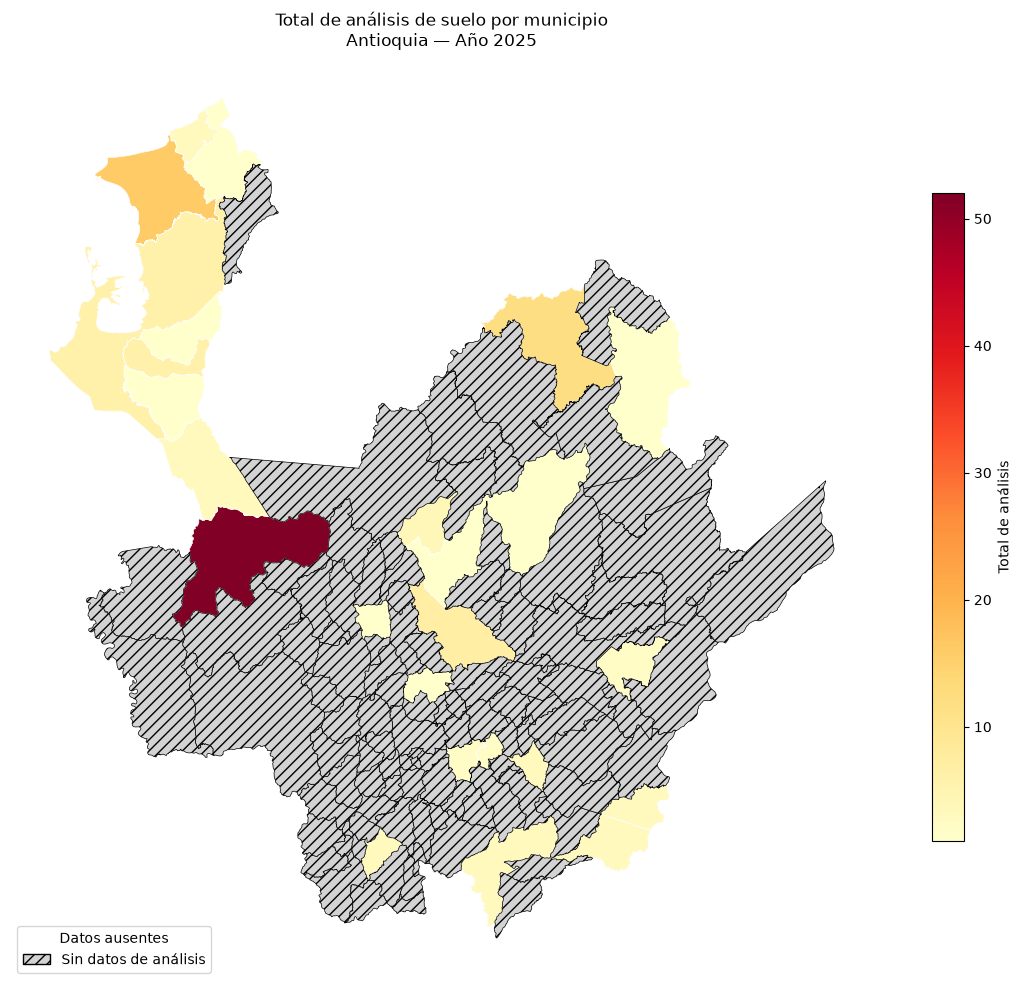

Mapa guardado en: /mnt/c/Users/TUPTC/bigdata/big-data-postgraduate/soluciones/mapa_analisis.png


In [15]:
# Desarrollo
# Une el resumen a los polígonos, calcula área en una proyección métrica y genera el mapa.

import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from pathlib import Path

# ============================================================
# 1. Elegir un año presente en suelo
# ============================================================

suelo_agro = tabla_final.copy()

anios_disponibles = sorted(
    suelo_agro["anio"].dropna().astype(int).unique()
)

if not anios_disponibles:
    raise ValueError("No hay años válidos en suelo.")

# Elegir el año más reciente disponible
anio_elegido = anios_disponibles[-1]

suelo_anual = suelo_agro.loc[
    suelo_agro["anio"] == anio_elegido
].copy()

print("Años disponibles:", anios_disponibles)
print("Año elegido:", anio_elegido)
print("Análisis del año:", len(suelo_anual))


# ============================================================
# 2. Preparar código municipal y pH válido
# ============================================================

# Se conserva el código como texto para evitar perder ceros iniciales
suelo_anual["codigo_municipio"] = (
    suelo_anual["Código Municipio"]
    .astype("string")
    .str.strip()
)

# Si el código aún no existe, se debe construir desde la fuente
# de códigos municipales correspondiente, sin inventar equivalencias.

suelo_anual["ph"] = pd.to_numeric(
    suelo_anual["ph"],
    errors="coerce"
)

# Excluir códigos vacíos del resumen municipal
suelo_con_codigo = suelo_anual.loc[
    suelo_anual["codigo_municipio"].notna()
    & suelo_anual["codigo_municipio"].ne("")
].copy()

# Una fila por código municipal
resumen_anual = (
    suelo_con_codigo
    .groupby("codigo_municipio", as_index=False)
    .agg(
        total_analisis=("codigo_municipio", "size"),
        ph_validos=("ph", "count"),
        media_ph_valido=("ph", "mean")
    )
)

# Conservar el año elegido en el resultado
resumen_anual["anio"] = anio_elegido

print("\nResumen anual:")
display(resumen_anual.head())


# ============================================================
# 3. Preparar los municipios y verificar las claves
# ============================================================

municipios_validos1 = municipios_validos.copy()

# Conservar el CRS y la geometría activa del GeoDataFrame original
if municipios_validos1.crs is None:
    raise ValueError(
        "municipios_validos no tiene CRS definido. "
        "Verifica el CRS real de la fuente antes de continuar."
    )

municipios_validos1["codigo_municipio"] = (
    municipios_validos1["mpio_cdpmp"]
    .astype("string")
    .str.strip()
)

# Comprobar claves vacías
print(
    "Códigos vacíos en municipios:",
    (
        municipios_validos1["codigo_municipio"].isna()
        | municipios_validos1["codigo_municipio"].eq("")
    ).sum()
)

print(
    "Códigos vacíos en resumen:",
    (
        resumen_anual["codigo_municipio"].isna()
        | resumen_anual["codigo_municipio"].eq("")
    ).sum()
)

# Comprobar unicidad de las claves para el merge one_to_one
duplicados_municipios = municipios_validos1.loc[
    municipios_validos1["codigo_municipio"].duplicated(keep=False),
    ["mpio_cdpmp", "codigo_municipio"]
]

duplicados_resumen = resumen_anual.loc[
    resumen_anual["codigo_municipio"].duplicated(keep=False),
    ["codigo_municipio"]
]

print("\nClaves duplicadas en municipios:")
display(duplicados_municipios.head(20))

print("\nClaves duplicadas en resumen:")
display(duplicados_resumen.head(20))

if not duplicados_municipios.empty:
    raise ValueError(
        "Hay códigos municipales duplicados en municipios_validos."
    )

if not duplicados_resumen.empty:
    raise ValueError(
        "Hay códigos municipales duplicados en resumen_anual."
    )

# ============================================================
# 4. Unión espacialmente conservadora
# ============================================================

# Evitar coincidencias de claves incompletas
municipios_para_merge = municipios_validos1.loc[
    municipios_validos1["codigo_municipio"].notna()
    & municipios_validos1["codigo_municipio"].ne("")
].copy()

resumen_para_merge = resumen_anual.loc[
    resumen_anual["codigo_municipio"].notna()
    & resumen_anual["codigo_municipio"].ne("")
].copy()

mapa_municipal = municipios_para_merge.merge(
    resumen_para_merge,
    on="codigo_municipio",
    how="left",
    validate="one_to_one",
    indicator=True
)

# Recuperar el GeoDataFrame y mantener geometría activa y CRS
mapa_municipal = gpd.GeoDataFrame(
    mapa_municipal,
    geometry=municipios_validos.geometry.name,
    crs=municipios_validos.crs
)

print("\nResultado de la unión:")
print(mapa_municipal["_merge"].value_counts())

# Municipios que no tienen resumen anual
municipios_sin_resumen = mapa_municipal.loc[
    mapa_municipal["_merge"] == "left_only",
    ["codigo_municipio", "mpio_cdpmp"]
].copy()

print("\nMunicipios sin resumen:")
display(municipios_sin_resumen)
print("--------------------")
municipios_sin_resumen.info()
print("--------------------")

# Códigos del resumen que no tienen geometría municipal
codigos_geometria = set(
    municipios_para_merge["codigo_municipio"].dropna()
)

resumen_sin_geometria = resumen_para_merge.loc[
    ~resumen_para_merge["codigo_municipio"].isin(codigos_geometria)
].copy()

print("\nCódigos del resumen sin geometría:")
display(resumen_sin_geometria)


# ============================================================
# 5. Calcular área en hectáreas usando EPSG:9377
# ============================================================

mapa_area = mapa_municipal.to_crs(epsg=9377).copy()

mapa_area["area_ha"] = (
    mapa_area.geometry.area / 10000
)

print("\nÁreas calculadas en hectáreas:")
display(
    mapa_area[
        ["codigo_municipio", "area_ha"]
    ].head(10)
)
print("-----------")
mapa_area.info()

# ============================================================
# 6. Crear mapa temático del departamento elegido
# ============================================================

departamento_elegido = "ANTIOQUIA"

# Ajusta el nombre de la columna si tu archivo usa otro encabezado
columna_departamento = "dpto_cnmbr"

if columna_departamento not in mapa_municipal.columns:
    raise KeyError(
        f"No existe la columna {columna_departamento!r}. "
        "Revisa mapa_municipal.columns y ajusta el nombre."
    )

mapa_depto = mapa_municipal.loc[
    mapa_municipal[columna_departamento]
    .astype("string")
    .str.strip()
    .str.upper()
    .eq(departamento_elegido.upper())
].copy()

if mapa_depto.empty:
    raise ValueError(
        f"No se encontraron municipios para {departamento_elegido}. "
        "Comprueba el nombre del departamento."
    )

# Categoría explícita para municipios sin datos
mapa_depto["total_analisis_mapa"] = (
    mapa_depto["total_analisis"].fillna(-1)
)

fig, ax = plt.subplots(figsize=(12, 10))

# Primero, dibujar todos los municipios con un color base
mapa_depto.plot(
    ax=ax,
    color="lightgrey",
    edgecolor="white",
    linewidth=0.5
)

# Municipios con datos: colorear por total de análisis
con_datos = mapa_depto.loc[
    mapa_depto["total_analisis"].notna()
]

if not con_datos.empty:
    con_datos.plot(
        column="total_analisis",
        ax=ax,
        cmap="YlOrRd",
        legend=True,
        edgecolor="white",
        linewidth=0.5,
        legend_kwds={
            "label": "Total de análisis",
            "shrink": 0.7
        }
    )

# Municipios sin datos: categoría visible en gris con trama
sin_datos = mapa_depto.loc[
    mapa_depto["total_analisis"].isna()
]

if not sin_datos.empty:
    sin_datos.plot(
        ax=ax,
        color="lightgrey",
        edgecolor="black",
        linewidth=0.5,
        hatch="///"
    )

    # Leyenda de la categoría sin datos
    from matplotlib.patches import Patch

    leyenda_sin_datos = Patch(
        facecolor="lightgrey",
        edgecolor="black",
        hatch="///",
        label="Sin datos de análisis"
    )

    ax.legend(
        handles=[leyenda_sin_datos],
        loc="lower left",
        title="Datos ausentes"
    )

ax.set_title(
    f"Total de análisis de suelo por municipio\n"
    f"{departamento_elegido.title()} — Año {anio_elegido}"
)

ax.set_axis_off()
fig.tight_layout()

# Guardar la imagen en el directorio de trabajo
ruta_salida = Path("mapa_analisis.png")

plt.savefig(
    ruta_salida,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("Mapa guardado en:", ruta_salida.resolve())


**Interpretación:**

_Se eligio el año 2025 y se vuelve a resumir los análisis asociados a una fila por código municipal, pH válidos y media de pH válido.Tambien se creo "codigo_municipio" desde municipios_validos, luego se comprobo que las claves de la tabla de agrosavia (tabla_final) y de municipios validos, fuera "codigo_municipio", para seguidamente hacer un merge y el resultado del mismo guardarlo en mapa_municipal, pero una cosa que me di cuenta con las tablas es que solo 445 elemento se les pudieron unir._

_Tambien se creo una copia con .to_crs(epsg=9377) y se calculo el área con la siguiente formula: area_ha = geometry.area / 10000. No se calculan las hectáreas directamente en grados en este caso, porque estan en un sistema diferente debido al uso del comando .to_crs._

_Con la informacion obtenida, se creo un mapa del departamento de Antioquia con todas las condiciones que solicitaba el taller, pero lo que más sobre sale del mismo es que entre más analisis de un municipio,más oscuro es su color, pero en caso de que no hallan datos de analisis solo se sombrea con lineas cruzadas. El mapa se guardo como "mapa_analisis.png". La mayor diferencia que se pudo ver entre DIVIPOLA 2024 y MGN 2025, es que se recogieron más datos en el 2024 que en 2025 y que a algunos lugares se les tomaron los dos años datos, mientras que en otros lugares solo se recogieron en el 2024, 2025 o en ninguno de los dos se recogieron datos ._ 


## 8. Intersección espacial con la muestra IGAC · 30 minutos

Proyecta copias de `municipios_validos` y `capacidad_valida` a EPSG:9377. Conserva una columna que identifique cada polígono IGAC a partir de su fila original. Selecciona solo códigos, identificador, atributos IGAC necesarios y geometría; evita nombres de columnas duplicados.

Ejecuta directamente `gpd.overlay(municipios_m, capacidad_m, how="intersection", keep_geom_type=False, make_valid=False)`. `make_valid=False` exige que hayas resuelto la validez de forma visible. Inspecciona los tipos resultantes, registra contactos de área cero y conserva las piezas poligonales de área positiva en `intersecciones`. Calcula hectáreas a partir de la geometría de cada pieza, no del atributo de área original.

Resume el área intersectada por municipio como `area_intersectada_ha` e intégrala a `mapa_municipal` con `validate="one_to_one"`. Para comparar geometrías originales y piezas, muestra un mapa de la extensión de la muestra y guárdalo como `mapa_interseccion.png`. No sumes áreas como cobertura única si hay solapamientos: diagnostica ese riesgo y explica el significado de la suma.

**Control:** presenta cantidad y área de piezas. Contrasta por polígono IGAC el área original y la suma intersectada, con tolerancia explícita y sin exigir igualdad si parte queda fuera de los municipios. Cinco polígonos son una muestra: no permiten estimar la capacidad de uso de un municipio completo. Esta intersección tampoco asigna una clase IGAC a una muestra individual AGROSAVIA.


Municipios
Geometrías iniciales: 1122
Geometrías inválidas: 0
Geometrías vacías o nulas: 0
Excluidas después de reparar: 0

Capacidad IGAC
Geometrías iniciales: 5
Geometrías inválidas: 0
Geometrías vacías o nulas: 0
Excluidas después de reparar: 0

Tipos geométricos resultantes:
Polygon         5
MultiPolygon    4
Name: count, dtype: int64

Contactos de área cero: 0

Cantidad de piezas poligonales: 9
Área total sumada de las piezas (ha): 4545.233534035797

Municipios en el mapa: 1122
Municipios con área intersectada: 5

Control de áreas por polígono IGAC:
 id_poligono_igac  area_original_ha  area_intersectada_ha  cantidad_piezas  diferencia_ha  dentro_tolerancia  supera_area_original
                0       1597.896924           1597.896924                2   9.322321e-12               True                 False
                1        359.443210            359.443210                1   1.136868e-13               True                 False
                2       1288.865623         

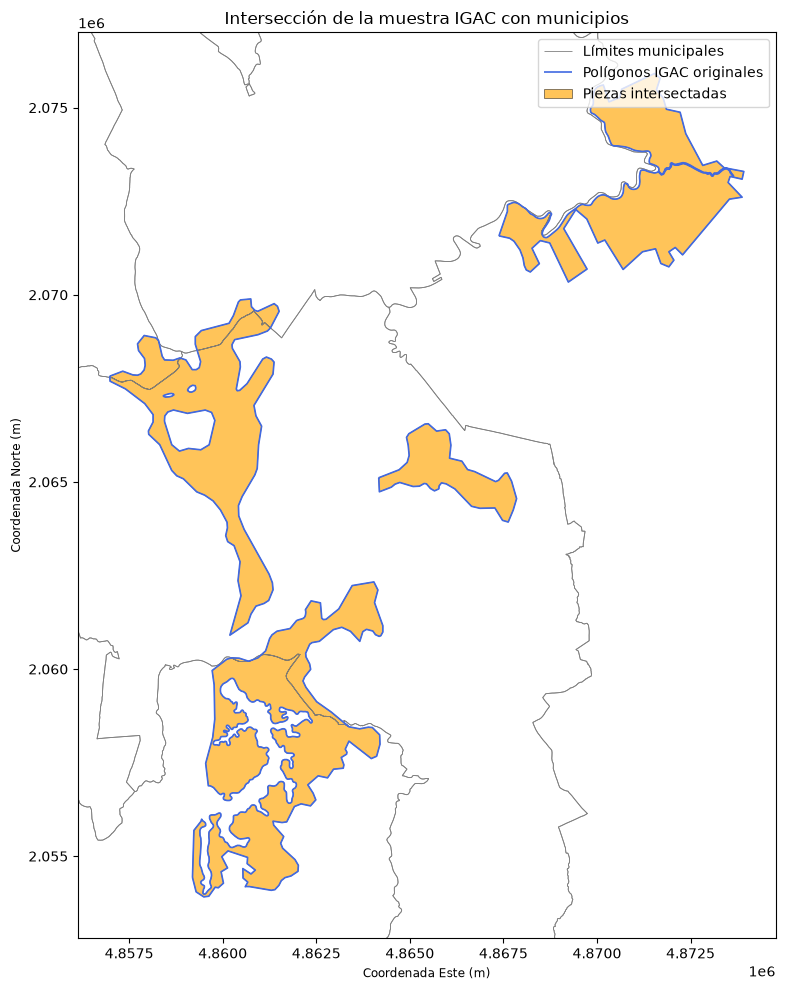


Mapa guardado como mapa_interseccion.png


In [16]:
# Desarrollo
# Intersecta con overlay, calcula áreas de piezas y explica los límites de la integración espacial.

import geopandas as gpd
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# ============================================================
# 1. CONFIGURACIÓN
# ============================================================

CRS_TRABAJO = "EPSG:9377"

# Tolerancia de comparación de áreas: 0.01 hectáreas = 100 m².
TOLERANCIA_HA = 0.01

# Ajusta esta lista a los atributos que existan en capacidad_valida.
# Incluye aquí la clase o código de capacidad de uso IGAC.
atributos_igac = [
    # "CLASE_CAPACIDAD",
    # "SUBCLASE",
]

# ============================================================
# 2. COMPROBAR Y PREPARAR LAS FUENTES
# ============================================================

assert isinstance(municipios_validos, gpd.GeoDataFrame)
assert isinstance(capacidad_valida, gpd.GeoDataFrame)
assert municipios_validos.crs is not None
assert capacidad_valida.crs is not None

assert "mpio_cdpmp" in municipios_validos.columns
assert municipios_validos.geometry.name in municipios_validos.columns

faltantes = set(atributos_igac) - set(capacidad_valida.columns)
assert not faltantes, f"Faltan atributos IGAC: {faltantes}"

# Identificador que conserva la fila original del polígono IGAC.
# Se crea antes de proyectar, filtrar o reparar geometrías.
capacidad_base = capacidad_valida.copy()
capacidad_base["id_poligono_igac"] = np.arange(
    len(capacidad_base), dtype="int64"
)

# Claves municipales como texto.
municipios_base = municipios_validos.copy()
municipios_base["codigo_municipio"] = (
    municipios_base["mpio_cdpmp"]
    .astype("string")
    .str.strip()
)

# Elimina claves incompletas para la intersección.
municipios_base = municipios_base.loc[
    municipios_base["codigo_municipio"].notna()
    & municipios_base["codigo_municipio"].ne("")
].copy()

# Seleccionar únicamente las columnas necesarias.
cols_municipios = [
    "codigo_municipio",
    municipios_base.geometry.name
]
municipios_base = municipios_base[cols_municipios].copy()

# Evitar que un código municipal tenga varios polígonos
# cuando el resumen posterior exige una fila por municipio.
assert municipios_base["codigo_municipio"].is_unique, (
    "Hay códigos municipales repetidos. "
    "Revisa si hay multipartes o polígonos municipales múltiples."
)


# Seleccionar atributos IGAC y renombrarlos con prefijo.
cols_igac = [
    "id_poligono_igac",
    *atributos_igac,
    capacidad_base.geometry.name
]
capacidad_base = capacidad_base[cols_igac].copy()
capacidad_base = capacidad_base.rename(
    columns={c: f"igac_{c}" for c in atributos_igac}
)

# Proyectar las copias a EPSG:9377.
municipios_m = municipios_base.to_crs(CRS_TRABAJO)
capacidad_m = capacidad_base.to_crs(CRS_TRABAJO)

# ============================================================
# 3. RESOLVER LA VALIDEZ ANTES DEL OVERLAY
# ============================================================

def reparar_geometrias(gdf, nombre):
    resultado = gdf.copy()

    vacias = resultado.geometry.isna() | resultado.geometry.is_empty
    invalidas = (
        ~vacias
        & ~resultado.geometry.is_valid
    )

    print(f"\n{nombre}")
    print("Geometrías iniciales:", len(resultado))
    print("Geometrías inválidas:", int(invalidas.sum()))
    print("Geometrías vacías o nulas:", int(vacias.sum()))

    # Reparación explícita de geometrías inválidas.
    resultado.loc[invalidas, "geometry"] = (
        resultado.loc[invalidas, "geometry"].make_valid()
    )

    # Excluir las geometrías nulas/vacías y las que sigan inválidas.
    vacias_despues = (
        resultado.geometry.isna()
        | resultado.geometry.is_empty
    )
    invalidas_despues = (
        ~vacias_despues
        & ~resultado.geometry.is_valid
    )

    excluidas = vacias_despues | invalidas_despues

    print("Excluidas después de reparar:", int(excluidas.sum()))

    resultado = resultado.loc[~excluidas].copy()

    assert resultado.geometry.is_valid.all()
    assert resultado.geometry.notna().all()
    assert (~resultado.geometry.is_empty).all()

    return resultado


municipios_m = reparar_geometrias(
    municipios_m, "Municipios"
)

capacidad_m = reparar_geometrias(
    capacidad_m, "Capacidad IGAC"
)

# Registrar el área de cada polígono IGAC en la proyección de trabajo.
# Si make_valid produjo una GeometryCollection, su área corresponde
# a la suma de sus componentes con área.
capacidad_m["area_original_ha"] = (
    capacidad_m.geometry.area / 10_000
)

# ============================================================
# 4. INTERSECCIÓN ESPACIAL DIRECTA
# ============================================================

cruce = gpd.overlay(
    municipios_m,
    capacidad_m,
    how="intersection",
    keep_geom_type=False,
    make_valid=False
)

print("\nTipos geométricos resultantes:")
print(cruce.geom_type.value_counts(dropna=False))

# Registrar todos los contactos sin área positiva.
cruce["area_pieza_ha"] = cruce.geometry.area / 10_000

contactos_cero = cruce.loc[
    cruce["area_pieza_ha"] <= 0
].copy()

print("\nContactos de área cero:", len(contactos_cero))
if not contactos_cero.empty:
    print(
        contactos_cero[
            [
                "codigo_municipio",
                "id_poligono_igac",
                "area_pieza_ha"
            ]
        ].head(20)
    )

# Conservar únicamente piezas poligonales de área positiva.
es_poligono = cruce.geom_type.isin(["Polygon", "MultiPolygon"])

intersecciones = cruce.loc[
    es_poligono & (cruce["area_pieza_ha"] > 0)
].copy()

assert intersecciones.geometry.is_valid.all()

print("\nCantidad de piezas poligonales:", len(intersecciones))
print(
    "Área total sumada de las piezas (ha):",
    intersecciones["area_pieza_ha"].sum()
)

# ============================================================
# 5. RESUMEN POR MUNICIPIO
# ============================================================

resumen_area = (
    intersecciones
    .groupby("codigo_municipio", as_index=False)
    .agg(
        area_intersectada_ha=("area_pieza_ha", "sum")
    )
)

# Asegurar una fila por municipio.
assert resumen_area["codigo_municipio"].is_unique

# Preparar el mapa municipal sin columnas duplicadas.
mapa_municipal = mapa_municipal.copy()

if "codigo_municipio" not in mapa_municipal.columns:
    mapa_municipal["codigo_municipio"] = (
        mapa_municipal["mpio_cdpmp"]
        .astype("string")
        .str.strip()
    )

assert mapa_municipal["codigo_municipio"].is_unique

# Quitar el resultado anterior, si se vuelve a ejecutar la celda.
mapa_municipal = mapa_municipal.drop(
    columns=["area_intersectada_ha"],
    errors="ignore"
)

mapa_municipal = mapa_municipal.merge(
    resumen_area,
    on="codigo_municipio",
    how="left",
    validate="one_to_one"
)

# Cero significa que no se registró una pieza intersectada.
mapa_municipal["area_intersectada_ha"] = (
    mapa_municipal["area_intersectada_ha"].fillna(0)
)

print("\nMunicipios en el mapa:", len(mapa_municipal))
print(
    "Municipios con área intersectada:",
    int((mapa_municipal["area_intersectada_ha"] > 0).sum())
)

# ============================================================
# 6. CONTRASTE DE ÁREA POR POLÍGONO IGAC
# ============================================================

area_por_igac = (
    intersecciones
    .groupby("id_poligono_igac", as_index=False)
    .agg(
        area_intersectada_ha=("area_pieza_ha", "sum"),
        cantidad_piezas=("area_pieza_ha", "size")
    )
)

control_igac = capacidad_m[
    ["id_poligono_igac", "area_original_ha"]
].merge(
    area_por_igac,
    on="id_poligono_igac",
    how="left",
    validate="one_to_one"
)

control_igac["area_intersectada_ha"] = (
    control_igac["area_intersectada_ha"].fillna(0)
)
control_igac["cantidad_piezas"] = (
    control_igac["cantidad_piezas"].fillna(0).astype(int)
)

control_igac["diferencia_ha"] = (
    control_igac["area_original_ha"]
    - control_igac["area_intersectada_ha"]
)

control_igac["dentro_tolerancia"] = (
    control_igac["diferencia_ha"].abs() <= TOLERANCIA_HA
)

control_igac["supera_area_original"] = (
    control_igac["area_intersectada_ha"]
    > control_igac["area_original_ha"] + TOLERANCIA_HA
)

print("\nControl de áreas por polígono IGAC:")
print(control_igac.to_string(index=False))
print("\nTolerancia aplicada (ha):", TOLERANCIA_HA)

# La intersección no tiene por qué cubrir el polígono completo.
# Diferencia positiva: parte del IGAC quedó fuera de los municipios.
# Diferencia negativa superior a tolerancia: investigar solapamientos,
# geometrías reparadas, duplicados o problemas de topología.

# ============================================================
# 7. DIAGNÓSTICO DE SOLAPAMIENTOS ENTRE PIEZAS
# ============================================================

# Comparar la suma de áreas con el área de la unión geométrica
# por municipio. La diferencia detecta doble conteo por solapamientos.
diagnostico_solapamientos = []

for codigo, grupo in intersecciones.groupby("codigo_municipio"):
    suma_ha = grupo.geometry.area.sum() / 10_000
    union_ha = grupo.geometry.union_all().area / 10_000

    diagnostico_solapamientos.append({
        "codigo_municipio": codigo,
        "suma_piezas_ha": suma_ha,
        "area_union_ha": union_ha,
        "exceso_suma_ha": suma_ha - union_ha
    })

diagnostico_solapamientos = pd.DataFrame(
    diagnostico_solapamientos
)

print("\nDiagnóstico de solapamientos:")
print(diagnostico_solapamientos.to_string(index=False))

# ============================================================
# 8. MAPA DE LA EXTENSIÓN DE LA MUESTRA
# ============================================================

fig, ax = plt.subplots(figsize=(10, 10))

# Límites municipales que intersectan la muestra.
municipios_m.boundary.plot(
    ax=ax,
    color="gray",
    linewidth=0.6,
    label="Límites municipales"
)

# Polígonos IGAC originales proyectados.
capacidad_m.boundary.plot(
    ax=ax,
    color="royalblue",
    linewidth=1.2,
    label="Polígonos IGAC originales"
)

# Piezas de la intersección.
if not intersecciones.empty:
    intersecciones.plot(
        ax=ax,
        color="orange",
        edgecolor="black",
        linewidth=0.5,
        alpha=0.65,
        label="Piezas intersectadas"
    )

# Ajustar la extensión a los polígonos IGAC de la muestra.
xmin, ymin, xmax, ymax = capacidad_m.total_bounds
dx = max(xmax - xmin, 1) * 0.05
dy = max(ymax - ymin, 1) * 0.05

ax.set_xlim(xmin - dx, xmax + dx)
ax.set_ylim(ymin - dy, ymax + dy)
ax.set_title("Intersección de la muestra IGAC con municipios")
ax.set_xlabel("Coordenada Este (m)")
ax.set_ylabel("Coordenada Norte (m)")
ax.set_aspect("equal")
ax.legend()
plt.tight_layout()

plt.savefig(
    "mapa_interseccion.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

print("\nMapa guardado como mapa_interseccion.png")


**Interpretación:**

_Se proyectaron copias de municipios_validos y capacidad_valida a EPSG:9377.Además, se conservo una columna que identifique cada polígono IGAC a partir de su fila original. Luego se  seleccionaron solo los códigos, identificador, atributos IGAC necesarios y geometría. Tambien se evito nombres de columnas duplicados y se resolvio la validez de forma visible. Posteriormente se inspecciono los tipos resultantes, se registraron los contactos de área cero y se conservaron las piezas poligonales de área positiva en intersecciones._

_Se calcula el valor de hectáreas a partir de la geometría de cada pieza, no del atributo de área original. Se resumio el área intersectada por municipio como area_intersectada_ha y se intégro a mapa_municipal con validate="one_to_one". Se realizo una comparacion de las  geometrías originales y piezas, con lo anterior se creo un mapa de la muestra, donde se puede ver que hay 5 lugares donde hay área intersectada . El mapa se guardo como mapa_interseccion.png._

_No se encontraron filas que tuvieran vacios,invalidos o que se necesitaron recuperar, pero si se hallo que en la integración espacial, la interseccion se puede cuantificar cuanto se superpone con los limites municipales, pero no permite estimar la distribucion completa  de la capacidad de uso de un  municipio._

## 9. Publicación y relectura · 35 minutos

Guarda `analisis_integrados.parquet` en OUT con `to_parquet(engine="pyarrow", compression="snappy", index=False)`. Incluye todas las filas, columnas originales, tipos definidos en el contrato, indicadores y procedencia. Usa nombres inequívocos para las coordenadas territoriales. Conserva `codigo_departamento` y `codigo_municipio` como texto; los códigos no resueltos permanecen ausentes.

Vuelve a leer mediante `pd.read_parquet(OUT + "/analisis_integrados.parquet", engine="pyarrow")`. Compara contenido ordenado por `id_fila`, tipos y cantidad de filas. Exporta a CSV controles, equivalencias, resumen y registros pendientes, sin índice. Escribe el contrato en una celda Markdown.

**Control:** reinicia el kernel y reejecuta; la salida debe conservar el mismo contenido. Las escrituras reemplazan archivos concretos de OUT. No modifiques los CSV originales.

Exporta `mapa_municipal` e `intersecciones` como capas separadas con llamadas explícitas:

```python
mapa_municipal.to_file(
    OUT + "/resultados_espaciales.gpkg", layer="municipios",
    driver="GPKG", engine="pyogrio", index=False
)
intersecciones.to_file(
    OUT + "/resultados_espaciales.gpkg", layer="intersecciones",
    driver="GPKG", engine="pyogrio", index=False
)
```
 Convierte explícitamente a texto las columnas categóricas, como el indicador del merge, antes de exportar si el controlador lo requiere. En cada reejecución crea un GeoPackage nuevo o reemplaza solo las capas indicadas; no uses append.

Relee cada capa con `gpd.read_file(OUT + "/resultados_espaciales.gpkg", layer="municipios", engine="pyogrio")` y la llamada equivalente para intersecciones. Verifica filas, claves, CRS, geometría activa, valores y áreas con tolerancia. Los tipos restaurados por GeoPackage pueden variar: documenta las diferencias. El Parquet tabular que usa PD05 conserva todas las observaciones y no lleva la geometría municipal repetida en cada análisis.


In [17]:
# Desarrollo
# Publica, vuelve a leer y valida el resultado con pd.testing.assert_frame_equal.

import os
import pandas as pd
from pathlib import Path
OUT = Path("OUT")
os.makedirs(OUT, exist_ok=True)

# Tabla final por análisis individual
analisis_integrados = integracion.copy()

ruta_parquet = OUT / "analisis_integrados.parquet"

# Exportar
analisis_integrados.to_parquet(
    ruta_parquet,
    engine="pyarrow",
    compression="snappy",
    index=False
)

# Leer nuevamente
df_parquet = pd.read_parquet(
    ruta_parquet,
    engine="pyarrow"
)

# Ordenar por el identificador estable
original_ordenado = (
    analisis_integrados
    .sort_values("id_fila")
    .reset_index(drop=True)
)

parquet_ordenado = (
    df_parquet
    .sort_values("id_fila")
    .reset_index(drop=True)
)

# Validaciones
assert len(analisis_integrados) == len(suelo)
assert len(df_parquet) == len(analisis_integrados)
assert df_parquet["id_fila"].is_unique
assert list(df_parquet.columns) == list(analisis_integrados.columns)

pd.testing.assert_frame_equal(
    original_ordenado,
    parquet_ordenado,
    check_dtype=True
)

print("Parquet guardado y validado correctamente.")
print("Filas:", len(df_parquet))
print("Columnas:", len(df_parquet.columns))
print("Tamaño:", os.path.getsize(ruta_parquet), "bytes")

print("\nTipos recuperados:")
display(df_parquet.dtypes)
pd.read_parquet(OUT / "analisis_integrados.parquet", engine="pyarrow")

Parquet guardado y validado correctamente.
Filas: 92738
Columnas: 54
Tamaño: 6249298 bytes

Tipos recuperados:


/tmp/ipykernel_5785/418304657.py:48: FutureWarning: Mismatched null-like values nan and None found. In a future version, pandas equality-testing functions (e.g. assert_frame_equal) will consider these not-matching and raise.
  pd.testing.assert_frame_equal(


id_fila                                        int64
Secuencial                                    object
Fecha de Análisis                             object
Departamento                                  object
Municipio                                     object
Cultivo                                       object
Estado                                        object
Tiempo de establecimiento                     object
Topografia                                    object
Drenaje                                       object
Riego                                         object
Fertilizantes aplicados                       object
pH agua:suelo                                 object
Materia organica                              object
Fósforo Bray II                               object
Azufre Fosfato monocalcico                    object
Acidez Intercambiable                         object
Aluminio intercambiable                       object
Calcio intercambiable                         

,id_fila,Secuencial,Fecha de Análisis,Departamento,Municipio,Cultivo,Estado,Tiempo de establecimiento,Topografia,Drenaje,...,longitud,Latitud,longitud_territorial,latitud_territorial,longitud_num,longitud_error_conversion,Latitud_num,Latitud_error_conversion,_merge,estado_union
0,0,1,7/01/2014,NARIÑO,SAN ANDRÉS DE TUMACO,No Indica,No indica,No indica,No indica,No indica,...,"-78,764073","1,807399",-78.764073,1.807399,-78.764073,False,1.807399,False,both,coincidencia
1,1,2,21/08/2014,HUILA,SANTA MARÍA,Granadilla,Establecido,De 1 a 5 años,Pendiente,Buen drenaje,...,"-75,586223","2,939603",-75.586223,2.939603,-75.586223,False,2.939603,False,both,coincidencia
2,2,3,22/08/2014,ANTIOQUIA,LIBORINA,Café,Por establecer,No indica,Pendiente,Mal drenaje,...,"-75,812838","6,677316",-75.812838,6.677316,-75.812838,False,6.677316,False,both,coincidencia
3,3,4,22/08/2014,ANTIOQUIA,LIBORINA,Maracuyá,Por establecer,No indica,Ondulado,Mal drenaje,...,"-75,812838","6,677316",-75.812838,6.677316,-75.812838,False,6.677316,False,both,coincidencia
4,4,5,22/08/2014,ANTIOQUIA,LIBORINA,Café,Por establecer,No indica,Ondulado,Mal drenaje,...,"-75,812838","6,677316",-75.812838,6.677316,-75.812838,False,6.677316,False,both,coincidencia
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
92733,92733,92734,7/04/2025,SANTANDER,SOCORRO,Cacao,ESTABLECIDO,De 0 a 1 año,Ligeramente ondulado,Regular drenaje,...,"-73,261198","6,46387",-73.261198,6.46387,-73.261198,False,6.46387,False,both,coincidencia
92734,92734,92735,4/04/2025,SANTANDER,PALMAS DEL SOCORRO,Cacao,ESTABLECIDO,de 5 a 10 años,Ligeramente ondulado,Buen drenaje,...,"-73,287764","6,406139",-73.287764,6.406139,-73.287764,False,6.406139,False,both,coincidencia
92735,92735,92736,3/04/2025,SANTANDER,PALMAS DEL SOCORRO,Cacao,ESTABLECIDO,mas de 10 años,Plano,Regular drenaje,...,"-73,287764","6,406139",-73.287764,6.406139,-73.287764,False,6.406139,False,both,coincidencia
92736,92736,92737,4/04/2025,SANTANDER,PALMAS DEL SOCORRO,Cacao,ESTABLECIDO,de 1 a 5 años,Pendiente moderada,Buen drenaje,...,"-73,287764","6,406139",-73.287764,6.406139,-73.287764,False,6.406139,False,both,coincidencia


In [18]:
mapa_municipal.to_file(
    OUT / "resultados_espaciales.gpkg", layer="municipios",
    driver="GPKG", engine="pyogrio", index=False
)
gpd.read_file(OUT / "resultados_espaciales.gpkg", layer="municipios", engine="pyogrio")
intersecciones.to_file(
    OUT / "resultados_espaciales.gpkg", layer="intersecciones",
    driver="GPKG", engine="pyogrio", index=False
)
gpd.read_file(OUT /"resultados_espaciales.gpkg", layer="intersecciones", engine="pyogrio")

,codigo_municipio,id_poligono_igac,area_original_ha,area_pieza_ha,geometry
0,11001,3,876.420920,874.791557,"MULTIPOLYGON (((4868105.208 2072293.941, 48681..."
1,11001,4,422.606857,422.606857,"MULTIPOLYGON (((4871855.852 2074957.929, 48722..."
2,25099,2,1288.865623,104.680216,"MULTIPOLYGON (((4858277.926 2068776.706, 48582..."
3,25473,2,1288.865623,89.257906,"MULTIPOLYGON (((4861265.658 2069123.433, 48612..."
4,25473,3,876.420920,1.629363,"MULTIPOLYGON (((4870807.304 2072939.291, 48707..."
5,25740,0,1597.896924,1253.729650,"MULTIPOLYGON (((4861898.878 2060164.234, 48618..."
6,25754,0,1597.896924,344.167274,"MULTIPOLYGON (((4863266.146 2058536.86, 486326..."
7,25754,1,359.443210,359.443210,"MULTIPOLYGON (((4865713.739 2066358.078, 48659..."
8,25754,2,1288.865623,1094.927501,"MULTIPOLYGON (((4856987.939 2067794.655, 48569..."


**Interpretación:**

_Se guardo analisis_integrados.parquet y luego se verifico.Tambien se conservaron las columnas codigo_departamento y codigo_municipio como texto.Luego se leyo mediante el comando "pd.read_parquet(OUT + "/analisis_integrados.parquet", engine="pyarrow")"._

_Tambien se exportaron los datos de mapa_municipal e intersecciones.Para seguidamente releer cada capa con el comando "gpd.read_file(OUT + "/resultados_espaciales.gpkg", layer="municipios", engine="pyogrio")", donde ademas se verifico filas, claves,crs, geometria entre otras cosas._

## Entrega

`soluciones/PD04_limpieza_integracion_territorial.ipynb`, con contrato, código visible, controles y tres conclusiones. Los resultados regenerables se guardan en `kit/salidas/soluciones/PD04/`. PD05 utiliza `analisis_integrados.parquet`; no elimines registros para facilitar esa actividad.

Incluye también los dos mapas PNG, el GeoPackage con municipios e intersecciones, el control de CRS y geometrías y la conciliación entre resumen tabular y mapa. PD05 reutiliza el Parquet de análisis y la capa municipal. Apoyo: [guía GeoPandas](../docs/manual-geopandas.md), [uniones de atributos y espaciales](https://geopandas.org/en/stable/docs/user_guide/mergingdata.html).
